# 12 · Dimensionality Reduction, Model Selection & Feature Engineering — Complete Reference

The model is only half the job. This notebook covers the three things that
decide whether a good model survives contact with real data:

1. **Dimensionality reduction** — why more features can *hurt*, and how PCA
   turns `p` correlated features into `k` informative components.
2. **Model selection** — cross-validation, data leakage and hyperparameter
   tuning: how to measure performance you can actually trust.
3. **Feature engineering** — missing values, skewness, scaling and encoding,
   wired into a single leakage-safe `ColumnTransformer` + `Pipeline` workflow.

| # | Section | Source session |
|---|---------|----------------|
| 1 | Curse of dimensionality | #178 |
| 2–4 | PCA (intuition → math → code) | #179–#181 |
| 5 | PCA end-to-end demo | #181 |
| 6 | Cross validation | #186 |
| 7 | Data leakage | #187 |
| 8 | Hyperparameter tuning | #188 |
| 9–10 | Feature engineering (missing values, transforms, encoding) | #199 |
| 11 | Complete ML workflow checklist + final demo | all of the above |

> **Note:** every code cell runs top-to-bottom in a fresh kernel with no
> internet access. All randomness is seeded (`random_state=42` / fixed RNGs).

## ▶ Sessions covered

| # | Session | Video |
|---|---------|-------|
| 178 | Curse of Dimensionality | https://www.youtube.com/watch?v=ToGuhynu-No |
| 179 | PCA Part 1 \| Geometric Intuition | https://www.youtube.com/watch?v=iRbsBi5W0-c |
| 180 | PCA Part 2 \| Problem Formulation and Step-by-Step Solution | https://www.youtube.com/watch?v=tXXnxjj2wM4 |
| 181 | PCA Part 3 \| Code Example and Visualization | https://www.youtube.com/watch?v=tofVCUDrg4M |
| 186 | Session on Cross Validation | https://www.youtube.com/watch?v=cY_pBnFM7fQ |
| 187 | Session on Data Leakage | https://www.youtube.com/watch?v=KHvcr0Q7jSk |
| 188 | Session on Hyperparameter Tuning | https://www.youtube.com/watch?v=cDmMVCC4dEE |
| 199 | Feature Engineering \| Handling Missing Values Part 1 | https://www.youtube.com/watch?v=e1-5NOwWCmo |

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import gammaln
from scipy.stats import boxcox, loguniform, randint, skew

from sklearn.datasets import make_classification
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import (PCA, FactorAnalysis, IncrementalPCA,
                                   KernelPCA, SparsePCA, TruncatedSVD)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activates IterativeImputer)
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (classification_report, f1_score, make_scorer,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupKFold, KFold, LeaveOneOut,
                                     RandomizedSearchCV, RepeatedKFold,
                                     StratifiedKFold, TimeSeriesSplit,
                                     cross_val_predict, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MaxAbsScaler, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, PowerTransformer, RobustScaler,
                                   StandardScaler)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
# Apple's Accelerate BLAS leaves sticky FP status flags behind, so numpy turns
# them into bogus RuntimeWarnings for EVERY `a @ b` (even for benign data).
# Filter only those; keep every other warning visible.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("numpy", np.__version__, "| pandas", pd.__version__)
import sklearn, scipy, seaborn
print("sklearn", sklearn.__version__, "| scipy", scipy.__version__, "| seaborn", seaborn.__version__)


numpy 2.2.6 | pandas 2.3.3
sklearn 1.7.2 | scipy 1.14.1 | seaborn 0.13.2


---
## 1. Curse of dimensionality — what breaks as dimensions grow

▶ Session #178 – Curse of Dimensionality: https://www.youtube.com/watch?v=ToGuhynu-No

Intuition says "more features → more information". Geometry disagrees. Two
things go wrong the moment `n_features` grows:

1. **The data becomes sparse.** Samples stop filling the feature space; each
   point becomes an isolated island. Rules of thumb ("10 samples per
   feature") break down exponentially, not linearly.
2. **Distances lose meaning.** In high dimensions *every* pair of points is
   almost equally far apart, so "nearest neighbour" stops being special —
   and every distance-based algorithm (KNN, k-means, DBSCAN, RBF-SVM,
   hierarchical clustering) quietly degrades to random guessing.

### Numeric demo 1 — the unit hypercube fills up with "shell"

In [2]:
# Everything inside eps of the surface is "shell"; only the inner core is
# genuinely "interior" data.  For the unit hypercube the core fraction is
# (1 - 2*eps)^n, so the shell fraction -> 1 exponentially fast.
eps = 0.1
dims = [1, 2, 5, 10, 20, 50, 100]

rows = []
for n in dims:
    core = (1 - 2 * eps) ** n
    shell = 1.0 - core
    # volume of the inscribed hypersphere (r = 0.5) relative to the cube,
    # computed in log-space because pi^(n/2) overflows for large n
    log_ratio = (n / 2) * np.log(np.pi) - gammaln(n / 2 + 1) + n * np.log(0.5)
    rows.append((n, shell, float(np.exp(log_ratio))))

cube_tbl = (pd.DataFrame(rows, columns=["n_features",
                                        "shell_fraction(eps=0.1)",
                                        "inscribed_sphere/cube"])
            .set_index("n_features"))
print("fraction of the unit hypercube lying in the outer eps-shell")
cube_tbl.round(6)


fraction of the unit hypercube lying in the outer eps-shell


,shell_fraction(eps=0.1),inscribed_sphere/cube
n_features,,
1,0.200000,1.000000
2,0.360000,0.785398
5,0.672320,0.164493
10,0.892626,0.002490
20,0.988471,0.000000
50,0.999986,0.000000
100,1.000000,0.000000


Read the table: with just **10 features already 88% of the volume is shell**,
and the largest inscribed sphere is 0.0025% of the cube. "Interior" data
essentially does not exist — everything you observe sits on a thin outer skin.

### Numeric demo 2 — nearest vs farthest distance

            mean_dist  std_dist  cv(=std/mean)  farthest/nearest
n_features                                                      
2               0.516     0.243          0.471           290.739
5               0.895     0.250          0.279            17.199
10              1.276     0.247          0.194             6.549
20              1.790     0.243          0.136             3.153
50              2.882     0.238          0.083             2.008
100             4.072     0.238          0.058             1.560


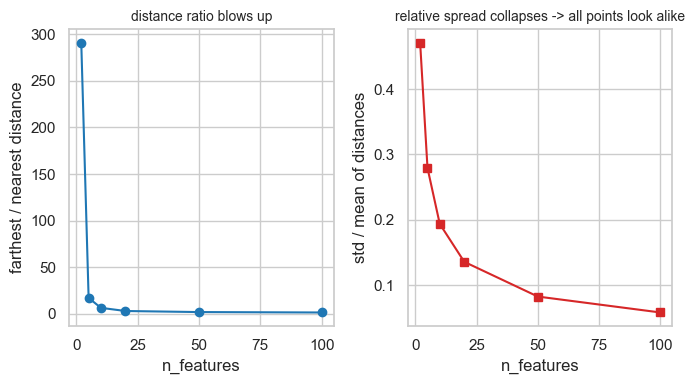

In [3]:
rng = np.random.default_rng(RANDOM_STATE)


def distance_stats(n_features, n_points=200, rng=None):
    """Mean / std / max-min ratio of all pairwise distances in U[0,1]^n."""
    pts = rng.random((n_points, n_features))
    d = np.sqrt(((pts[:, None, :] - pts[None, :, :]) ** 2).sum(-1))
    d = d[np.triu_indices(n_points, 1)]
    return d.mean(), d.std(), d.max() / d.min()


rows = []
for n in [2, 5, 10, 20, 50, 100]:
    mu, sd, ratio = distance_stats(n, rng=rng)
    rows.append({"n_features": n, "mean_dist": mu, "std_dist": sd,
                 "cv(=std/mean)": sd / mu, "farthest/nearest": ratio})

dist_df = pd.DataFrame(rows).set_index("n_features")
print(dist_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(7, 4), sharex=True)
axes[0].plot(dist_df.index, dist_df["farthest/nearest"], marker="o", color="tab:blue")
axes[0].set_ylabel("farthest / nearest distance")
axes[0].set_title("distance ratio blows up", fontsize=10)
axes[1].plot(dist_df.index, dist_df["cv(=std/mean)"], marker="s", color="tab:red")
axes[1].set_ylabel("std / mean of distances")
axes[1].set_title("relative spread collapses -> all points look alike", fontsize=10)
for ax in axes:
    ax.set_xlabel("n_features")
plt.tight_layout()
plt.show()


**What this means per algorithm**

| Algorithm | What high dimensions do to it |
|---|---|
| KNN | every point becomes its own neighbour; "nearest" ≈ random point |
| SVM (RBF / polynomial) | kernel on a distance that barely varies → almost linear |
| k-means / DBSCAN / hierarchical | cluster structure dissolves into uniform noise |
| distance-based anomaly detection | nothing is anomalous, everything is equidistant |
| Linear models (L2-regularised) | mostly fine — see the "when high-dim is fine" note below |

**"You need exponentially more data"**

| n_features | grid points for just 10 divisions/axis | you need |
|---|---|---|
| 2 | 10² = 100 | a few hundred rows is plenty |
| 5 | 10⁵ = 100,000 | ~10⁵ rows to keep the same density |
| 10 | 10¹⁰ = 10 billion | more rows than you will ever have |
| 20 | 10²⁰ | ≈ atoms in the observable universe |

Density decays like `1 / d^n` — the curse is **exponential in n**, which is
why throwing in "just a few more features" is so expensive.

**When is high dimensionality fine?**

- **Linear models with regularisation** (Ridge, Lasso, LogisticRegression):
  they do not rely on neighbourhoods, and the penalty keeps the extra
  coefficients from exploding. Text/TF-IDF with 50k columns works *because*
  the model is linear + regularised.
- **Tree models** pick splits feature-by-feature; irrelevant features mostly
  just cost time (though they do add split-search noise).
- High `p` only becomes fatal when `p` grows while `n` stays fixed — that
  is the overfitting regime (see the bias/variance discussion in §6).

**Mitigations**

| Mitigation | Idea | Covered in |
|---|---|---|
| PCA / dimensionality reduction | keep the directions that carry variance | §2–§5 |
| Feature selection | drop uninformative columns outright | §10 comparison |
| Regularisation | let the model shrink useless coefficients | model-specific |
| Domain knowledge | never add a feature you cannot justify | your head |
| More data | the only honest cure for the exponential grid | — |

**Section notes — curse of dimensionality:**

| Symptom | Numerical evidence above |
|---|---|
| data becomes a thin shell | shell fraction → 1 as `n_features` grows |
| sphere/cube volume → 0 | inscribed sphere is 0.0025% of the cube at n=10 |
| distances concentrate | `farthest/nearest` ↑ while `std/mean` ↓ |
| need exponentially more data | grid density `10^n` divisions |
| safe high-dim models | regularised linear models, trees |

---
## 2. PCA — geometric intuition

▶ Session #179 – PCA Part 1 | Geometric Intuition: https://www.youtube.com/watch?v=iRbsBi5W0-c

PCA answers one question: **if I had to squish this cloud of points onto a
single line (or a k-D plane), which line loses the least information?**

- **Projection** — dropping every point perpendicularly onto a candidate
  line. Points that were far apart can end up on top of each other; the
  variance lost is exactly the variance perpendicular to the line.
- **Direction of maximum variance** — PCA picks the line on which the
  projected points are *most spread out*. Maximum spread ⇒ maximum retained
  information (for centred data, spread = variance).
- **Principal component = eigenvector of the covariance matrix** —
  maximising `variance = wᵀ C w` subject to `‖w‖ = 1` is a Lagrange problem
  whose solution is `C w = λ w`. The unit eigenvectors `w` are the principal
  directions, the eigenvalues `λ` are the variance captured along each.
  Components are ordered `λ₁ ≥ λ₂ ≥ …`, so **PC1 is the top eigenvector**.

means after centering : [-0.04865  -0.030154]
covariance matrix     :
 [[0.8852 0.7716]
 [0.7716 0.912 ]]
eigenvalues           : [1.6703 0.1268]
PC1 (unit vector)     : [0.701 0.713]
PC2 (unit vector)     : [-0.713  0.701]


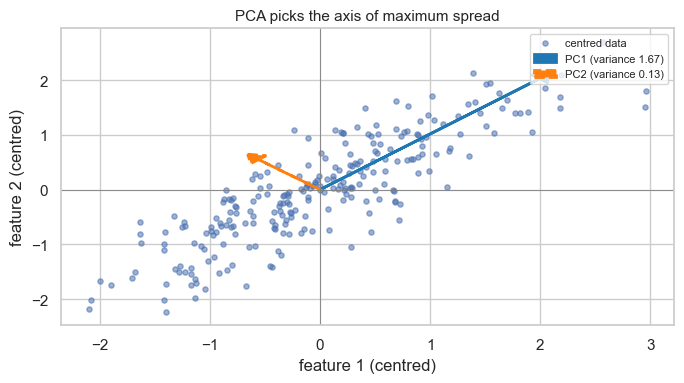

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(0, 1, n)
x2 = 0.85 * x1 + rng.normal(0, 0.5, n)
X2 = np.column_stack([x1, x2])          # raw 2-D data (kept for §4 as well)

mu2 = X2.mean(axis=0)
Xc = X2 - mu2                            # mean-centred
C = np.cov(Xc, rowvar=False)             # 2x2 covariance matrix
evals, evecs = np.linalg.eigh(C)         # symmetric solver -> ascending order
order = np.argsort(evals)[::-1]
evals, evecs = evals[order], evecs[:, order]

print("means after centering :", mu2.round(6))
print("covariance matrix     :\n", C.round(4))
print("eigenvalues           :", evals.round(4))
print("PC1 (unit vector)     :", evecs[:, 0].round(3))
print("PC2 (unit vector)     :", evecs[:, 1].round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(Xc[:, 0], Xc[:, 1], s=14, alpha=0.55, label="centred data")
length = 2.2 * np.sqrt(evals)
for i, (col, ls) in enumerate(zip(["tab:blue", "tab:orange"], ["-", "--"])):
    ax.arrow(0, 0, length[i] * evecs[0, i], length[i] * evecs[1, i],
             head_width=0.2, head_length=0.14, fc=col, ec=col, lw=2, ls=ls,
             label=f"PC{i + 1} (variance {evals[i]:.2f})")
ax.axhline(0, lw=0.6, color="grey")
ax.axvline(0, lw=0.6, color="grey")
ax.set_xlabel("feature 1 (centred)")
ax.set_ylabel("feature 2 (centred)")
ax.set_title("PCA picks the axis of maximum spread", fontsize=11)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


### Mean-centering is mandatory

PCA maximises variance *around the mean*. If the cloud does not sit at the
origin, the direction of largest spread of `XᵀX` is dominated by where the
cloud *is*, not by its shape. `sklearn.decomposition.PCA` centers
internally (`X - self.mean_`), so you never need to do it by hand — but you
must remember it when you write the maths (or your own implementation).
The cell below shifts the same 2-D cloud far from the origin and compares
the two directions.

In [5]:
# same shape, but the cloud does NOT sit at the origin
X_off = X2 + np.array([40.0, -60.0])


def raw_pc1(mat, center):
    """Top eigenvector of the (possibly un-centred) second-moment matrix."""
    M = mat - mat.mean(axis=0) if center else mat
    w, v = np.linalg.eigh(M.T @ M / (len(M) - 1))
    return v[:, np.argmax(w)]


pc1_nocenter = raw_pc1(X_off, center=False)
pc1_centered = raw_pc1(X_off, center=True)
ang = np.degrees(np.arccos(np.clip(abs(np.dot(pc1_nocenter, pc1_centered)), -1.0, 1.0)))

print("data mean (PCA needs this to be 0):", X_off.mean(axis=0).round(1))
print("PC1 without centering             :", pc1_nocenter.round(3))
print("PC1 with centering                :", pc1_centered.round(3))
print(f"angle between them                 : {ang:.1f} degrees  <- wrong direction")
print("(without centering you measure where the cloud IS, not how it is shaped)")


data mean (PCA needs this to be 0): [ 40. -60.]
PC1 without centering             : [-0.554  0.833]
PC1 with centering                : [0.701 0.713]
angle between them                 : 78.1 degrees  <- wrong direction
(without centering you measure where the cloud IS, not how it is shaped)


### Standardization matters when features have different units

PCA operates on the **covariance matrix** (or, after standardizing, on the
**correlation matrix**).

| You feed PCA… | Equivalent to analysing | dominated by |
|---|---|---|
| raw features | covariance matrix | features with the biggest variance (big units) |
| standardized features (z-scores) | correlation matrix | the *pattern* of correlation, scale-free |

Rule of thumb: **standardize unless all features share the same unit and
comparable ranges** (e.g. all pixel intensities 0–255). Age-in-years vs
salary-in-rupees without standardizing → PC1 is literally "salary".

In [6]:
rng = np.random.default_rng(0)
n = 300
age = rng.normal(32, 8, n)                       # years
salary = 800 * age + rng.normal(0, 4000, n)      # rupees (same signal, huge scale)
X_scale = np.column_stack([age, salary])

print("feature stds        :", X_scale.std(axis=0).round(1))
print("raw covariance diag :", np.diag(np.cov(X_scale, rowvar=False)).round(0))


def pca_summary(mat, label):
    p = PCA().fit(mat)
    print(f"{label:20s} PC1 = {np.round(p.components_[0], 3)}   "
          f"explained = {np.round(p.explained_variance_ratio_, 3)}")


pca_summary(X_scale, "raw (covariance)")
pca_summary((X_scale - X_scale.mean(0)) / X_scale.std(0), "standardized")


feature stds        : [   8.1 7732.7]
raw covariance diag : [6.7000000e+01 5.9995132e+07]
raw (covariance)     PC1 = [0.001 1.   ]   explained = [1. 0.]
standardized         PC1 = [0.707 0.707]   explained = [0.932 0.068]


**Section notes — PCA intuition:**

| Idea | One-liner |
|---|---|
| projection | drop points perpendicularly onto a line/plane |
| best line | the one where projected points are most spread out |
| principal component | eigenvector of the covariance matrix, ordered by eigenvalue |
| eigenvalue | variance captured along that component |
| centering | subtract the mean before measuring spread |
| standardization | z-scores first when features have different units |

---
## 3. PCA — problem formulation & step-by-step solution

▶ Session #180 – PCA Part 2 | Problem Formulation and Step-by-Step Solution: https://www.youtube.com/watch?v=tXXnxjj2wM4

### The 5 steps of PCA (memorise these)

1. **Standardize** the features → mean 0, variance 1 (skip only if all
   features share units/scales).
2. Build the **covariance matrix** `C = (1/(n-1)) Zᵀ Z` (p × p).
3. **Eigendecomposition** of `C` → eigenvalues `λ₁ ≥ … ≥ λₚ` and unit
   eigenvectors.
4. **Sort** eigenvalues descending, keep the top `k` eigenvectors →
   projection matrix `W` (p × k).
5. **Project**: `Z_k = Z W` — the new k-dimensional representation.

Equivalent formulation (what sklearn actually solves): PCA = **rank-k
approximation via SVD** of the centred matrix. `np.linalg.svd` and
`np.linalg.eigh(C)` give the same directions; the SVD version is numerically
stabler and is what `svd_solver` uses.

In [7]:
feat_names = [f"f{i}" for i in range(8)]
X_all, y_all = make_classification(n_samples=600, n_features=8, n_informative=5,
                                   n_redundant=2, random_state=RANDOM_STATE)
X_std = (X_all - X_all.mean(axis=0)) / X_all.std(axis=0)     # step 1

C = np.cov(X_std, rowvar=False)                               # step 2
print("covariance shape:", C.shape, "| symmetric:", np.allclose(C, C.T))
print(pd.DataFrame(C.round(3), index=feat_names, columns=feat_names).to_string())


covariance shape: (8, 8) | symmetric: True
       f0     f1     f2     f3     f4     f5     f6     f7
f0  1.002 -0.224  0.147  0.079 -0.902  0.716  0.045 -0.109
f1 -0.224  1.002 -0.403 -0.695  0.168 -0.460 -0.042 -0.734
f2  0.147 -0.403  1.002 -0.035 -0.396 -0.017 -0.023 -0.069
f3  0.079 -0.695 -0.035  1.002  0.089  0.129  0.037  0.357
f4 -0.902  0.168 -0.396  0.089  1.002 -0.440 -0.034  0.182
f5  0.716 -0.460 -0.017  0.129 -0.440  1.002  0.046  0.391
f6  0.045 -0.042 -0.023  0.037 -0.034  0.046  1.002  0.045
f7 -0.109 -0.734 -0.069  0.357  0.182  0.391  0.045  1.002


### `np.linalg.eigh` vs `np.linalg.eig`

| Function | Use for | Guarantees |
|---|---|---|
| `np.linalg.eigh` | **symmetric / Hermitian** matrices (covariance!) | real eigenvalues, ascending order, orthogonal vectors, faster |
| `np.linalg.eig` | any square matrix | eigenvalues may come back **complex** (tiny imaginary parts), arbitrary order |

> **Gotcha:** a covariance matrix is symmetric by construction, so always use
> `eigh`. Using `eig` on float data often returns `0.9999+1e-17j` style
> values that break `argsort` and `np.allclose` comparisons.

In [8]:
w_eigh, v_eigh = np.linalg.eigh(C)                 # symmetric solver
w_eig, v_eig = np.linalg.eig(C)                    # general solver
print("eigh (ascending) :", np.round(w_eigh, 5))
print("eig  (unsorted)  :", np.round(np.real(w_eig), 5))
print("imag parts from eig:", np.round(np.imag(w_eig), 12))
print("same set after sorting:",
      np.allclose(np.sort(w_eig.real)[::-1], w_eigh[::-1]))


eigh (ascending) : [-0.       0.       0.25329  0.73088  0.98747  1.15506  2.07574  2.81091]
eig  (unsorted)  : [ 2.81091  2.07574  1.15506  0.98747  0.73088  0.25329 -0.       0.     ]
imag parts from eig: [0. 0. 0. 0. 0. 0. 0. 0.]
same set after sorting: True


### Explained variance & the "80% rule"

- `explained_variance_` = eigenvalues `λᵢ` (variance in each component)
- `explained_variance_ratio_` = `λᵢ / Σλ` (fraction of total variance)
- **cumulative ratio** tells you how many components you need: stop at the
  elbow, conventionally where the cumulative curve crosses **80%** (or 95%
  when you want to be conservative).

     eigenvalue    evr  cumulative
PC1       2.811  0.351       0.351
PC2       2.076  0.259       0.610
PC3       1.155  0.144       0.754
PC4       0.987  0.123       0.877
PC5       0.731  0.091       0.968
PC6       0.253  0.032       1.000
PC7       0.000  0.000       1.000
PC8       0.000  0.000       1.000
components for 80% variance: 4   |   for 95%: 5


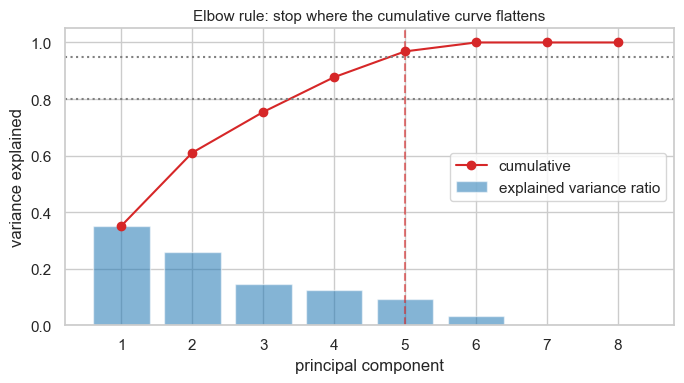

In [9]:
pca_full = PCA().fit(X_std)
ev, evr = pca_full.explained_variance_, pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
k80 = int(np.searchsorted(cum, 0.80) + 1)
k95 = int(np.searchsorted(cum, 0.95) + 1)

print(pd.DataFrame({"eigenvalue": ev.round(3),
                    "evr": evr.round(3),
                    "cumulative": cum.round(3)},
                   index=[f"PC{i + 1}" for i in range(len(evr))]).to_string())
print(f"components for 80% variance: {k80}   |   for 95%: {k95}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(evr) + 1), evr, alpha=0.55, color="tab:blue",
       label="explained variance ratio")
ax.plot(range(1, len(cum) + 1), cum, marker="o", color="tab:red",
        label="cumulative")
ax.axhline(0.80, ls=":", color="grey")
ax.axhline(0.95, ls=":", color="grey")
ax.axvline(k95, ls="--", color="tab:red", alpha=0.6)
ax.set_xlabel("principal component")
ax.set_ylabel("variance explained")
ax.set_title("Elbow rule: stop where the cumulative curve flattens", fontsize=11)
ax.legend(loc="center right")
plt.tight_layout()
plt.show()


### From-scratch PCA vs `sklearn.decomposition.PCA`

Four tiny functions — `_standardize`, `_cov`, `_eig`, `project` — reproduce
exactly what sklearn computes.

In [10]:
def _standardize(X):
    """Step 1: z-scores with population std (ddof=0), like StandardScaler."""
    mu = X.mean(axis=0)
    sd = X.std(axis=0, ddof=0)
    return (X - mu) / sd


def _cov(Xz):
    """Step 2: sample covariance (ddof=1) — the same normalisation sklearn uses."""
    return np.cov(Xz, rowvar=False)


def _eig(C):
    """Step 3+4: eigendecomposition of a symmetric matrix, sorted descending."""
    vals, vecs = np.linalg.eigh(C)
    idx = np.argsort(vals)[::-1]
    return vals[idx], vecs[:, idx]


def project(X, n_components):
    """Step 1-5: return (scores, all eigenvalues, top-k components)."""
    Xz = _standardize(X)
    vals, vecs = _eig(_cov(Xz))
    comps = vecs[:, :n_components]
    return Xz @ comps, vals, comps


Z_mine, evals_mine, comps_mine = project(X_all, 3)

pca_sk = PCA(n_components=3).fit(X_std)          # we standardised manually above
Z_sk = pca_sk.transform(X_std)

# a component's sign is arbitrary -> align before comparing
signs = np.sign(np.sum(Z_mine * Z_sk, axis=0))
Z_aligned = Z_mine * signs
comps_aligned = comps_mine * signs

print("projections allclose :", np.allclose(Z_aligned, Z_sk, atol=1e-8))
print("eigenvalues allclose :", np.allclose(evals_mine[:3],
                                            pca_sk.explained_variance_))
print("components allclose  :", np.allclose(comps_aligned, pca_sk.components_.T,
                                            atol=1e-8))


projections allclose : True
eigenvalues allclose : True
components allclose  : True


### Reconstruction & reconstruction error

`inverse_transform(transform(X))` projects back onto the k-PC subspace. The
leftover error is exactly the variance you threw away:

`‖Z - Ẑ‖²_F = (n - 1) · Σ_{discarded} λᵢ`

which is also why the reconstruction error drops to 0 when `k = p`.

In [11]:
def recon_mse(mat, k):
    p = PCA(n_components=k).fit(mat)
    return float(np.mean((mat - p.inverse_transform(p.transform(mat))) ** 2))


mse_rows = []
for k in range(1, X_std.shape[1] + 1):
    mse_rows.append({"k": k, "reconstruction_MSE": recon_mse(X_std, k),
                     "variance_kept": PCA(n_components=k).fit(X_std)
                     .explained_variance_ratio_.sum()})
mse_tbl = pd.DataFrame(mse_rows).set_index("k")
print(mse_tbl.round(4).to_string())

k = 3
predicted = (len(X_std) - 1) * evals_mine[k:].sum() / (len(X_std) * X_std.shape[1])
print(f"\nMSE from inverse_transform (k={k})   :", round(recon_mse(X_std, k), 6))
print(f"(n-1) * discarded_eigenvalues / (n*p):", round(predicted, 6))
print("match:", np.isclose(recon_mse(X_std, k), predicted, rtol=1e-4))


   reconstruction_MSE  variance_kept
k                                   
1              0.6492         0.3508
2              0.3902         0.6098
3              0.2460         0.7540
4              0.1228         0.8772
5              0.0316         0.9684
6              0.0000         1.0000
7              0.0000         1.0000
8              0.0000         1.0000

MSE from inverse_transform (k=3)   : 0.246044
(n-1) * discarded_eigenvalues / (n*p): 0.246044
match: True


### Interpreting components — loadings

`pca.components_[i]` is the eigenvector for PC(i+1): one weight per *original*
feature. The weight's magnitude tells you how much that original feature
contributes to the component — this is what makes PCA interpretable.

      PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
f0 -0.454 -0.407 -0.199 -0.057  0.194 -0.050  0.701 -0.230
f1  0.474 -0.380 -0.244 -0.028  0.017  0.013  0.245  0.714
f2 -0.207 -0.136  0.806  0.177 -0.237  0.287  0.207  0.277
f3 -0.267  0.422  0.054  0.019  0.764  0.079  0.013  0.397
f4  0.391  0.480 -0.087 -0.027 -0.076  0.557  0.496 -0.214
f5 -0.473 -0.067 -0.406 -0.151 -0.272  0.617 -0.280  0.225
f6 -0.051  0.019 -0.242  0.968 -0.037  0.024  0.000  0.000
f7 -0.274  0.508 -0.134 -0.066 -0.491 -0.465  0.284  0.326


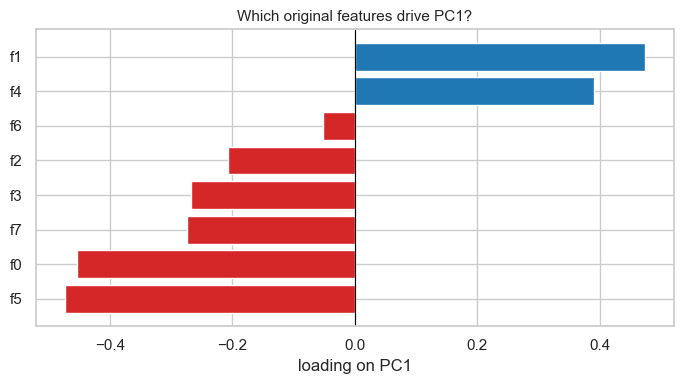

In [12]:
loadings = pd.DataFrame(pca_full.components_.T, index=feat_names,
                        columns=[f"PC{i + 1}" for i in range(pca_full.n_components_)])
print(loadings.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
pc1 = loadings["PC1"].sort_values()
ax.barh(pc1.index, pc1.values, color=["tab:red" if v < 0 else "tab:blue"
                                      for v in pc1.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("loading on PC1")
ax.set_title("Which original features drive PC1?", fontsize=11)
plt.tight_layout()
plt.show()


### Sign ambiguity — not a bug

`w` and `-w` define the *same* line, so an eigenvector's sign is arbitrary
( LAPACK may return either, and it can flip between sklearn versions).
What must be consistent is the pairing of **scores** with **components**:
flip one, flip the other, reconstruction is identical.

In [13]:
pca_flip = PCA(n_components=3).fit(X_std)
# flip the sign of PC1 only: still the same line, still a valid PCA model
pca_flip.components_ = pca_flip.components_ * np.array([[-1.0], [1.0], [1.0]])

Z_plain = pca_sk.transform(X_std)
Z_flipped = pca_flip.transform(X_std)
print("|scores| identical      :", np.allclose(np.abs(Z_plain), np.abs(Z_flipped)))
print("PC1 scores are negatives:", np.allclose(Z_plain[:, 0], -Z_flipped[:, 0]))
print("reconstruction identical:",
      np.allclose(pca_sk.inverse_transform(Z_plain),
                  pca_flip.inverse_transform(Z_flipped)))
print("explained variance identical:",
      np.allclose(pca_sk.explained_variance_, pca_flip.explained_variance_))


|scores| identical      : True
PC1 scores are negatives: True
reconstruction identical: True
explained variance identical: True


**Section notes — PCA maths:**

| Step | Code |
|---|---|
| 1. standardize | `StandardScaler().fit_transform(X)` |
| 2. covariance | `np.cov(Z, rowvar=False)` |
| 3. eigendecomposition | `np.linalg.eigh(C)` (symmetric!) |
| 4. sort eigenvalues | `np.argsort(vals)[::-1]` |
| 5. project | `Z @ comps[:, :k]` or `pca.transform(X)` |
| variance report | `explained_variance_`, `explained_variance_ratio_` |
| go back | `pca.inverse_transform(pca.transform(X))` |

> **Gotcha:** `eigh` returns eigenvalues **ascending** — always reverse them.
> And never interpret a component's sign; use `abs(loadings)` when ranking
> feature importance.

---
## 4. PCA — code example & visualization

▶ Session #181 – PCA Part 3 | Code Example and Visualization: https://www.youtube.com/watch?v=tofVCUDrg4M

### 2-D data → 1 component → reconstruction

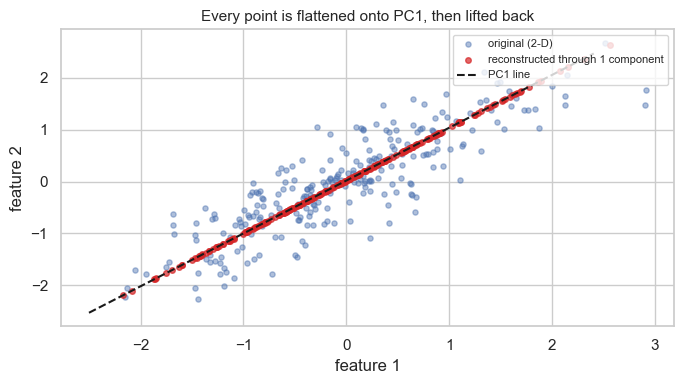

variance kept by 1 component : 0.929
shape: (250, 2) -> (250, 1) -> (250, 2)


In [14]:
pca1 = PCA(n_components=1).fit(X2)          # PCA centres internally
Z1 = pca1.transform(X2)
X_rec = pca1.inverse_transform(Z1)

span = np.linspace(-3.5, 3.5, 100)
line = np.outer(span, pca1.components_[0]) + pca1.mean_   # (100, 2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X2[:, 0], X2[:, 1], s=14, alpha=0.45, label="original (2-D)")
ax.scatter(X_rec[:, 0], X_rec[:, 1], s=16, color="tab:red", alpha=0.7,
           label="reconstructed through 1 component")
ax.plot(line[:, 0], line[:, 1], "k--", lw=1.5, label="PC1 line")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
ax.set_title("Every point is flattened onto PC1, then lifted back", fontsize=11)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()
print("variance kept by 1 component :", round(pca1.explained_variance_ratio_[0], 3))
print("shape:", X2.shape, "->", Z1.shape, "->", X_rec.shape)


### The canonical sklearn pipeline: `StandardScaler → PCA → classifier`

In [15]:
Xtr4, Xte4, ytr4, yte4 = train_test_split(X_all, y_all, test_size=0.25,
                                          random_state=RANDOM_STATE, stratify=y_all)

# NOTE: PCA lives inside the pipeline, so it is fitted on the training fold
# only — the holdout never influences the components (see §6, §7a).
pipe_demo = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=4)),
    ("clf", LogisticRegression(max_iter=1000)),
])
pipe_demo.fit(Xtr4, ytr4)
print("holdout accuracy       :", round(pipe_demo.score(Xte4, yte4), 3))
print("X :", Xtr4.shape, "-> pipeline[:-1].transform ->", pipe_demo[:-1].transform(Xtr4).shape)
print("PC variance kept       :", round(pipe_demo.named_steps["pca"]
                                        .explained_variance_ratio_.sum(), 3))


holdout accuracy       : 0.747
X : (450, 8) -> pipeline[:-1].transform -> (450, 4)
PC variance kept       : 0.88


### `PCA(n_components=...)` — three ways to choose `k`

| Mode | Meaning |
|---|---|
| `n_components=None` | keep **all** components (p of them) |
| `n_components=k` (int) | keep exactly k components |
| `n_components=0.95` (float, 0<n<1) | keep the smallest k that explains 95% of variance |

Inspecting first, then deciding, is the honest workflow:

explained_variance_ (raw eigenvalues): [2.811 2.076 1.155 0.987 0.731 0.253 0.    0.   ]
explained_variance_ratio_            : [0.351 0.259 0.144 0.123 0.091 0.032 0.    0.   ]
cumulative                          : [0.351 0.61  0.754 0.877 0.968 1.    1.    1.   ]
first k with cumsum >= 0.95 : 5  (equivalent to PCA(n_components=0.95))
PCA(n_components=0.95).n_components_ -> 5


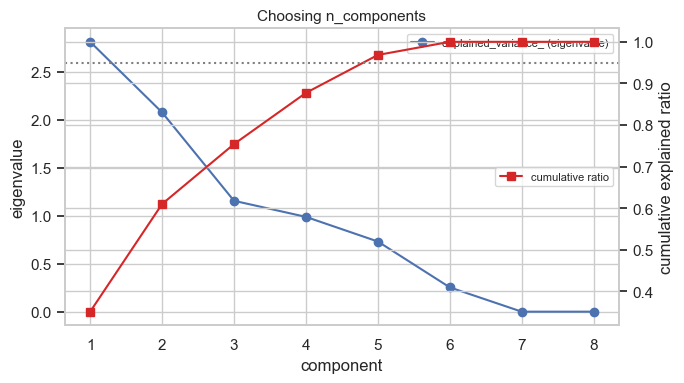

In [16]:
probe = PCA().fit(StandardScaler().fit_transform(X_all))
print("explained_variance_ (raw eigenvalues):", probe.explained_variance_.round(3))
print("explained_variance_ratio_            :", probe.explained_variance_ratio_.round(3))
cum = np.cumsum(probe.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print("cumulative                          :", cum.round(3))
print(f"first k with cumsum >= 0.95 : {k95}"
      f"  (equivalent to PCA(n_components=0.95))")
print("PCA(n_components=0.95).n_components_ ->",
      PCA(n_components=0.95).fit(StandardScaler().fit_transform(X_all)).n_components_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum) + 1), probe.explained_variance_, marker="o",
        label="explained_variance_ (eigenvalue)")
ax.set_xlabel("component"); ax.set_ylabel("eigenvalue")
ax2 = ax.twinx()
ax2.plot(range(1, len(cum) + 1), cum, marker="s", color="tab:red",
         label="cumulative ratio")
ax2.axhline(0.95, ls=":", color="grey")
ax2.set_ylabel("cumulative explained ratio")
ax.set_title("Choosing n_components", fontsize=11)
ax.legend(loc="upper right", fontsize=8)
ax2.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()


### `transform` / `inverse_transform` semantics

- `fit(X)` — computes `mean_`, `components_`, `explained_variance_`
- `transform(X)` — centers with `mean_` then projects: `(X - mean_) @ components_.T`
- `inverse_transform(Z)` — lifts back: `Z @ components_ + mean_`
  (an approximation — only exact if you kept all p components)

In [17]:
p2 = PCA(n_components=2).fit(X_all)          # no scaling: PCA only centres
Z2 = p2.transform(X_all)
back = p2.inverse_transform(Z2)

print("X", X_all.shape, "-> transform ->", Z2.shape, "-> inverse_transform ->", back.shape)
print("mean_ equals X.mean(0):", np.allclose(p2.mean_, X_all.mean(axis=0)))
print("variance kept with 2 PCs:", round(p2.explained_variance_ratio_.sum(), 3))
print("mean squared information lost:", round(np.mean((X_all - back) ** 2), 4))


X (600, 8) -> transform -> (600, 2) -> inverse_transform -> (600, 8)
mean_ equals X.mean(0): True
variance kept with 2 PCs: 0.755
mean squared information lost: 0.8067


### PCA variants — pick the right tool

| Estimator | Use when |
|---|---|
| `PCA(svd_solver="randomized")` | `X` is huge (>10⁴ rows) — randomized SVD, `n_components` required (this *is* the old `RandomizedPCA`) |
| `IncrementalPCA(batch_size=...)` | data does not fit in memory — feeds mini-batches through `partial_fit` |
| `KernelPCA(kernel="rbf"/"poly", fit_inverse_transform=True)` | structure is **non-linear** — kernel trick, no `inverse_transform` by default |
| `SparsePCA` | you want **sparse** loadings (only a few original features per component) → interpretable |
| `TruncatedSVD` | input is a **sparse matrix** (TF-IDF text) — works without centering |
| `FactorAnalysis(random_state=...)` | you believe latent factors + independent noise (statistical model, not variance maximisation) |
| `LinearDiscriminantAnalysis` | **supervised** reduction — maximises class separation, ≤ n_classes-1 components |

Every variant is a drop-in `fit_transform` — same input, same `(n, k)` output:

In [18]:
X_var, y_var = make_classification(n_samples=300, n_features=8, n_informative=5,
                                   n_redundant=2, random_state=RANDOM_STATE)
variant_models = [
    ("PCA(svd_solver='randomized')",
     PCA(n_components=3, svd_solver="randomized", random_state=RANDOM_STATE)),
    ("IncrementalPCA(batch_size=100)", IncrementalPCA(n_components=3, batch_size=100)),
    ("KernelPCA(kernel='rbf')",
     KernelPCA(n_components=3, kernel="rbf", random_state=RANDOM_STATE)),
    ("SparsePCA", SparsePCA(n_components=3, random_state=RANDOM_STATE)),
    ("TruncatedSVD", TruncatedSVD(n_components=3, random_state=RANDOM_STATE)),
    ("FactorAnalysis", FactorAnalysis(n_components=3, random_state=RANDOM_STATE)),
]
for name, model in variant_models:
    Zv = model.fit_transform(X_var)
    print(f"{name:34s} -> {Zv.shape}")

lda = LinearDiscriminantAnalysis(n_components=1)   # supervised: n_components <= n_classes - 1
print(f"{'LinearDiscriminantAnalysis':34s} -> {lda.fit_transform(X_var, y_var).shape}")


PCA(svd_solver='randomized')       -> (300, 3)
IncrementalPCA(batch_size=100)     -> (300, 3)
KernelPCA(kernel='rbf')            -> (300, 3)


SparsePCA                          -> (300, 3)
TruncatedSVD                       -> (300, 3)


FactorAnalysis                     -> (300, 3)
LinearDiscriminantAnalysis         -> (300, 1)


**When NOT to use PCA**

- **Interpretability matters** — after PCA nobody can say "the model uses
 `age`"; it uses "0.4·age − 0.2·salary + …". Prefer feature selection or
  plain domain features when stakeholders ask *why*.
- **Mostly categorical data** — z-scoring one-hot columns is meaningless;
  use MCA / feature selection instead.
- **Genuinely non-linear structure** (concentric circles, Swiss roll): PCA
  only finds *linear* directions. Reach for `KernelPCA`, **t-SNE** or
  **UMAP** (visualisation only — they do not `transform` new data
  consistently, so they are not a drop-in preprocessing step).
- **Duplicate / near-duplicate features** — PCA hides the problem instead of
  fixing it; drop or merge the duplicates first.

**PCA vs feature selection**

| | PCA | Feature selection |
|---|---|---|
| Output | new components (combinations) | a subset of the *original* columns |
| Supervision | unsupervised (target ignored) | filter/wrapper methods can use the target |
| Interpretability | lost (mixtures) | kept (real columns) |
| Collinearity | removed by construction | must be handled separately |
| Cost with wide data | SVD on p×p can be expensive | cheap filters (variance, correlation) |
| Typical use | visualisation, decorrelation, speed | explanation, deployment constraints |

**Section notes — PCA in code:**

| Task | API |
|---|---|
| fit & project | `PCA(k).fit(X)` → `.transform(X)` |
| back-project | `.inverse_transform(Z)` |
| choose k | `explained_variance_ratio_.cumsum()` ≥ 0.95 |
| see k chosen for you | `PCA(n_components=0.95).n_components_` |
| big data | `svd_solver="randomized"` / `IncrementalPCA` |
| sparse data | `TruncatedSVD` |
| non-linear | `KernelPCA` / t-SNE / UMAP |

---
## 5. PCA end-to-end demo — 4 features → 2 PCs → model

▶ Session #181 – PCA Part 3 | Code Example and Visualization: https://www.youtube.com/watch?v=tofVCUDrg4M

PC variance ratio : [0.395 0.25 ] -> total 0.645


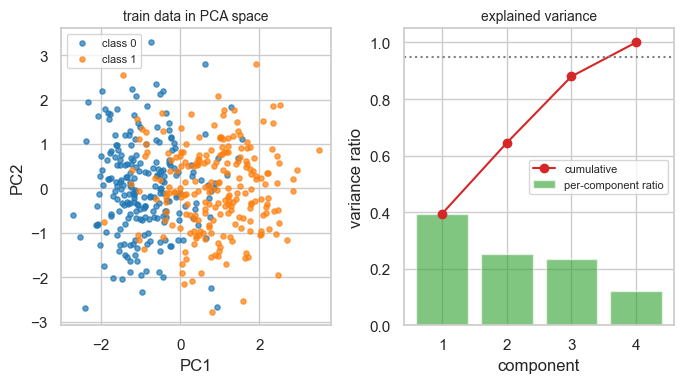

               model_input  n_features  holdout_accuracy  fit+score_s
        all 4 raw features           4              0.90       0.0032
top 2 principal components           2              0.88       0.0030

NOTE: with only 4 features PCA is a *fair* fight, not a win — its value
      shows up on wide, correlated data (see the 95% table in §4).


In [19]:
rng = np.random.default_rng(RANDOM_STATE)
X5, y5 = make_classification(n_samples=600, n_features=4, n_informative=3,
                             n_redundant=0, random_state=RANDOM_STATE)
X5 = pd.DataFrame(X5, columns=["f0", "f1", "f2", "f3"])
Xtr5, Xte5, ytr5, yte5 = train_test_split(X5, y5, test_size=0.25,
                                          random_state=RANDOM_STATE, stratify=y5)

scaler5 = StandardScaler().fit(Xtr5)            # fit on TRAIN only
Ztr5, Zte5 = scaler5.transform(Xtr5), scaler5.transform(Xte5)

pca2 = PCA(n_components=2).fit(Ztr5)
Ttr, Tte = pca2.transform(Ztr5), pca2.transform(Zte5)
print("PC variance ratio :", pca2.explained_variance_ratio_.round(3),
      "-> total", round(pca2.explained_variance_ratio_.sum(), 3))

full5 = PCA().fit(Ztr5)
fig, axes = plt.subplots(1, 2, figsize=(7, 4))
for cls, col in [(0, "tab:blue"), (1, "tab:orange")]:
    axes[0].scatter(Ttr[ytr5 == cls, 0], Ttr[ytr5 == cls, 1], s=14, alpha=0.7,
                    color=col, label=f"class {cls}")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title("train data in PCA space", fontsize=10)
axes[0].legend(fontsize=8)

cum5 = np.cumsum(full5.explained_variance_ratio_)
axes[1].bar(range(1, 5), full5.explained_variance_ratio_, alpha=0.6,
            color="tab:green", label="per-component ratio")
axes[1].plot(range(1, 5), cum5, marker="o", color="tab:red", label="cumulative")
axes[1].axhline(0.95, ls=":", color="grey")
axes[1].set_xlabel("component"); axes[1].set_ylabel("variance ratio")
axes[1].set_title("explained variance", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


def timed_fit_score(model, Xtr, ytr, Xte, yte):
    """Fit + score, wall-clock seconds."""
    t0 = time.perf_counter()
    model.fit(Xtr, ytr)
    acc = model.score(Xte, yte)
    return acc, time.perf_counter() - t0


acc_all, t_all = timed_fit_score(LogisticRegression(max_iter=2000),
                                 Xtr5, ytr5, Xte5, yte5)
acc_pc, t_pc = timed_fit_score(LogisticRegression(max_iter=2000),
                               Ttr, ytr5, Tte, yte5)

cmp_tbl = pd.DataFrame([
    {"model_input": "all 4 raw features", "n_features": 4,
     "holdout_accuracy": acc_all, "fit+score_s": t_all},
    {"model_input": "top 2 principal components", "n_features": 2,
     "holdout_accuracy": acc_pc, "fit+score_s": t_pc},
])
print(cmp_tbl.round(4).to_string(index=False))
print("\nNOTE: with only 4 features PCA is a *fair* fight, not a win — its value")
print("      shows up on wide, correlated data (see the 95% table in §4).")


**Section notes — PCA end-to-end:**

```
raw X -> fit scaler on TRAIN -> transform -> PCA(k).fit(TRAIN) -> transform
                                            -> classifier -> predictions
```

| Check | Why |
|---|---|
| scaler and PCA both `fit` on train only | test statistics must never influence preprocessing (§7) |
| keep all steps in one `Pipeline` | one `.fit`, zero chance of a forgotten step |
| report `explained_variance_ratio_.sum()` | says how much signal your k PCs keep |

---
## 6. Cross validation

▶ Session #186 – Session on Cross Validation: https://www.youtube.com/watch?v=cY_pBnFM7fQ

A **single** train/test split gives you one draw from the sampling
distribution of your metric. Change `random_state` and the number changes —
sometimes enough to reverse a model comparison. CV turns that one noisy
estimate into `k` estimates you can average and spread.

model  LogisticRegression  RandomForest
seed                                   
0                   0.776         0.904
1                   0.752         0.864
2                   0.832         0.912
3                   0.856         0.896
4                   0.776         0.880

spread (max - min) over the 5 splits:
model
LogisticRegression    0.104
RandomForest          0.048


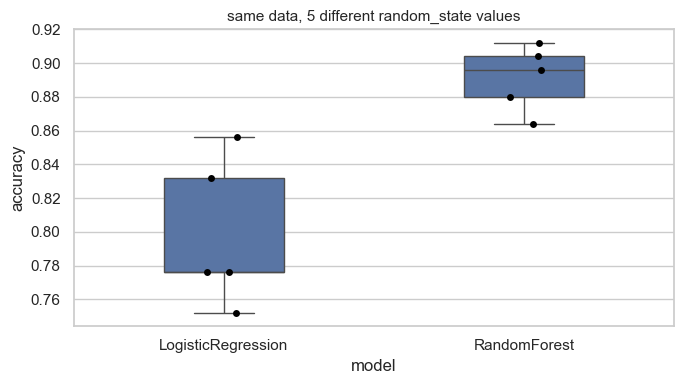

In [20]:
X6, y6 = make_classification(n_samples=500, n_features=10, n_informative=6,
                             n_redundant=2, random_state=RANDOM_STATE)

rows = []
for seed in [0, 1, 2, 3, 4]:
    Xtr, Xte, ytr, yte = train_test_split(X6, y6, test_size=0.25,
                                          random_state=seed, stratify=y6)
    lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE).fit(Xtr, ytr)
    rows.append({"seed": seed, "model": "LogisticRegression", "accuracy": lr.score(Xte, yte)})
    rows.append({"seed": seed, "model": "RandomForest", "accuracy": rf.score(Xte, yte)})

split_df = pd.DataFrame(rows)
print(split_df.pivot(index="seed", columns="model", values="accuracy").round(3).to_string())
print("\nspread (max - min) over the 5 splits:")
print(split_df.groupby("model")["accuracy"].agg(lambda s: round(s.max() - s.min(), 3)).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=split_df, x="model", y="accuracy", ax=ax, width=0.4, fliersize=0)
sns.stripplot(data=split_df, x="model", y="accuracy", ax=ax, color="black",
              size=5, jitter=0.06)
ax.set_title("same data, 5 different random_state values", fontsize=11)
plt.tight_layout()
plt.show()


### k-fold intuition

```text
k = 5,  rows 0..9

fold 1   [ TEST | train | train | train | train ]   score_1
fold 2   [ train | TEST | train | train | train ]   score_2
fold 3   [ train | train | TEST | train | train ]   score_3
fold 4   [ train | train | train | TEST | train ]   score_4
fold 5   [ train | train | train | train | TEST ]   score_5
                                                    ────────
                                         CV score = mean(scores)
                                         spread   = std(scores)
```

Every row is **tested exactly once** and trained on `k-1` folds. You get `k`
accuracy numbers instead of one, and `mean ± std` is the estimate you quote.

### `KFold` / `cross_val_score` / `cross_validate`

### `sklearn.model_selection.KFold(n_splits=5, shuffle=False, random_state=None)`
**What it does:** splits indices into `k` consecutive folds.
**Syntax:** `KFold(n_splits=5, shuffle=False, random_state=None)`
**Parameters:**
- `n_splits` — int — number of folds (must be ≥ 2) — default `5`
- `shuffle` — bool — shuffle before splitting; **required** if the data has order
- `random_state` — int/None — seed used when `shuffle=True`
**Returns:** an iterable of `(train_indices, test_indices)` from `.split(X, y)`

### `cross_val_score(estimator, X, y=None, cv=None, scoring=None)`
**What it does:** runs k-fold CV and returns the score array for the test folds.
**Syntax:** `cross_val_score(est, X, y, cv=5, scoring="accuracy")`
**Parameters:**
- `estimator` — fitted-agnostic model implementing `.fit`/`.score`
- `cv` — int / CV splitter / None — number of folds or an explicit splitter
- `scoring` — str / None — metric name; `None` uses `estimator.score`
**Returns:** `np.ndarray` of shape `(n_splits,)` — **you** aggregate (`mean`, `std`)

### `cross_validate(estimator, X, y, cv=None, scoring=None, return_train_score=False)`
**What it does:** like `cross_val_score` but returns a dict with timings, train
scores and multiple metrics at once.
**Returns:** dict with `fit_time`, `score_time`, `test_<metric>`, and optionally
`train_<metric>` / `estimator`

In [21]:
# TIP: shuffle=True only for IID data — leave shuffle=False (or use
# TimeSeriesSplit) when rows are ordered in time (see §7d).
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(LogisticRegression(max_iter=1000), X6, y6,
                         cv=kf, scoring="accuracy")
print("fold scores :", scores.round(3))
print(f"CV accuracy : {scores.mean():.3f} ± {scores.std():.3f}")

res = cross_validate(LogisticRegression(max_iter=1000), X6, y6, cv=5,
                     return_train_score=True,
                     scoring={"acc": "accuracy", "f1": "f1"})
cv_tbl = pd.DataFrame({"train_acc": res["train_acc"], "test_acc": res["test_acc"],
                       "train_f1": res["train_f1"], "test_f1": res["test_f1"]},
                      index=[f"fold {i + 1}" for i in range(5)])
print(cv_tbl.round(3).to_string())
print(f"test acc {res['test_acc'].mean():.3f} ± {res['test_acc'].std():.3f} | "
      f"train acc {res['train_acc'].mean():.3f}  "
      "(train >> test would mean overfitting)")


fold scores : [0.81 0.78 0.79 0.83 0.8 ]
CV accuracy : 0.802 ± 0.017
        train_acc  test_acc  train_f1  test_f1
fold 1      0.818      0.82     0.816    0.809
fold 2      0.822      0.77     0.818    0.753
fold 3      0.822      0.80     0.821    0.796
fold 4      0.808      0.82     0.803    0.816
fold 5      0.815      0.80     0.809    0.818
test acc 0.802 ± 0.018 | train acc 0.817  (train >> test would mean overfitting)


### Stratified K-fold — never let a fold lose a class

With imbalanced targets, plain `KFold` can hand a fold **zero** positives →
that fold's score is meaningless (and `scoring="recall"` can even error).
`StratifiedKFold` keeps each fold's class proportions equal to the dataset's.

In [22]:
X_im, y_im = make_classification(n_samples=500, n_features=10, n_informative=6,
                                 weights=[0.95, 0.05], flip_y=0.02,
                                 random_state=RANDOM_STATE)
print("overall class balance:", np.round(np.bincount(y_im) / len(y_im), 3))


def fold_table(splitter, name):
    out = []
    for i, (_, te) in enumerate(splitter.split(X_im, y_im)):
        cnt = np.bincount(y_im[te], minlength=2)
        out.append({"splitter": name, "fold": i + 1,
                    "class_0": cnt[0], "class_1": cnt[1]})
    return pd.DataFrame(out)


strat_tbl = pd.concat([
    fold_table(KFold(5, shuffle=True, random_state=RANDOM_STATE), "KFold"),
    fold_table(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), "StratifiedKFold"),
], ignore_index=True)
print(strat_tbl.to_string(index=False))
print("\nmin class_1 per fold  ->  KFold:", strat_tbl[strat_tbl.splitter == 'KFold'].class_1.min(),
      " StratifiedKFold:", strat_tbl[strat_tbl.splitter == 'StratifiedKFold'].class_1.min())


overall class balance: [0.946 0.054]
       splitter  fold  class_0  class_1
          KFold     1       93        7
          KFold     2       95        5
          KFold     3       98        2
          KFold     4       96        4
          KFold     5       91        9
StratifiedKFold     1       95        5
StratifiedKFold     2       95        5
StratifiedKFold     3       95        5
StratifiedKFold     4       94        6
StratifiedKFold     5       94        6

min class_1 per fold  ->  KFold: 2  StratifiedKFold: 5


### Choosing the splitter

| Splitter | When | Cost |
|---|---|---|
| `StratifiedKFold` | **classification, imbalanced** (default choice) | k fits |
| `KFold` | regression or balanced data (shuffle first!) | k fits |
| `LeaveOneOut` | tiny data (n < ~50), need the most optimistic estimate | **n fits** |
| `RepeatedKFold` | want a tighter error bar without paying for more folds | k × r fits |
| `GroupKFold` | rows from the same **group** (patient/user/session) must stay together | k fits |
| `TimeSeriesSplit` | temporal data — train only on the past | k fits |

In [23]:
loo_small = cross_val_score(LogisticRegression(max_iter=1000), X6[:60], y6[:60],
                            cv=LeaveOneOut())
print(f"LOOCV on 60 rows: {loo_small.mean():.3f} ± {loo_small.std():.3f} "
      f"({len(loo_small)} model fits!)")
print("LOOCV on all 500 rows would need", len(list(LeaveOneOut().split(X6))), "fits")

rep = cross_val_score(LogisticRegression(max_iter=1000), X6, y6,
                      cv=RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE))
print(f"\nRepeatedKFold(5x3): {rep.mean():.3f} ± {rep.std():.3f}  over {len(rep)} estimates")


LOOCV on 60 rows: 0.733 ± 0.442 (60 model fits!)
LOOCV on all 500 rows would need 500 fits

RepeatedKFold(5x3): 0.802 ± 0.031  over 15 estimates


### `GroupKFold` — group leakage

If one patient/user contributes several rows, a random split puts the same
group in **train and test**. The model has already "seen" that group's other
rows → the test score measures memorisation, not generalisation.

In [24]:
rng = np.random.default_rng(RANDOM_STATE)
n_groups, per_group = 40, 5
groups = np.repeat(np.arange(n_groups), per_group)
Xg = rng.normal(size=(n_groups * per_group, 4))
yg = (Xg[:, 0] + 0.5 * Xg[:, 1] + rng.normal(size=len(Xg)) * 0.3 > 0).astype(int)


def group_overlap(splitter, X, y, groups):
    """How many groups appear on BOTH sides of each fold? (0 = safe)"""
    if isinstance(splitter, GroupKFold):
        splits = splitter.split(X, y, groups)
    else:
        splits = splitter.split(X, y)          # KFold ignores groups (and warns)
    return [len(set(groups[tr]) & set(groups[te])) for tr, te in splits]


print("KFold    — groups present in BOTH sides per fold:",
      group_overlap(KFold(5, shuffle=True, random_state=RANDOM_STATE), Xg, yg, groups))
print("GroupKFold — same count (must be all zeros):",
      group_overlap(GroupKFold(n_splits=5), Xg, yg, groups))


KFold    — groups present in BOTH sides per fold: [25, 26, 26, 28, 28]
GroupKFold — same count (must be all zeros): [0, 0, 0, 0, 0]


### `TimeSeriesSplit` — random CV leaks the future

For time-ordered data a random fold puts **future rows in training** and asks
the model to predict the past. Chronological folds guarantee
`max(train_date) < min(test_date)`.

In [25]:
dates = pd.date_range("2023-01-01", periods=240, freq="D")
rng = np.random.default_rng(RANDOM_STATE)
sales = 100 + 0.15 * np.arange(240) + rng.normal(0, 4, 240)
df_ts = pd.DataFrame({"date": dates, "sales": sales})
df_ts["lag_1"] = df_ts["sales"].shift(1)          # only past information
df_ts = df_ts.dropna().reset_index(drop=True)

tscv = TimeSeriesSplit(n_splits=5)
for i, (tr, te) in enumerate(tscv.split(df_ts)):
    print(f"fold {i + 1}: train {df_ts.date.iloc[tr[0]].date()} -> "
          f"{df_ts.date.iloc[tr[-1]].date()}  |  "
          f"test {df_ts.date.iloc[te[0]].date()} -> {df_ts.date.iloc[te[-1]].date()}")

ktr, kte = next(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(df_ts))
first_test = df_ts.date.iloc[kte].min()
leak_count = int((df_ts.date.iloc[ktr] > first_test).sum())
print(f"\nrandom KFold: {leak_count} training rows are dated AFTER the first "
      f"test row  ->  future leaked into training")


fold 1: train 2023-01-02 -> 2023-02-14  |  test 2023-02-15 -> 2023-03-25
fold 2: train 2023-01-02 -> 2023-03-25  |  test 2023-03-26 -> 2023-05-03
fold 3: train 2023-01-02 -> 2023-05-03  |  test 2023-05-04 -> 2023-06-11
fold 4: train 2023-01-02 -> 2023-06-11  |  test 2023-06-12 -> 2023-07-20
fold 5: train 2023-01-02 -> 2023-07-20  |  test 2023-07-21 -> 2023-08-28

random KFold: 185 training rows are dated AFTER the first test row  ->  future leaked into training


### The pipeline-safe CV rule

> **Gotcha:** any transformer that *learns* parameters (mean, std, quantiles,
> category lists, PCA directions) must be **re-fitted inside every training
> fold**. Fitting it once on the full `X` before calling `cross_val_score`
> feeds each validation fold's own statistics back into its model — a
> preprocessing leak (§7a).

In [26]:
# WRONG: the scaler saw all 500 rows (including every validation fold)
X_leaky = StandardScaler().fit_transform(X6)
right_lr = Pipeline([("s", StandardScaler()), ("m", LogisticRegression(max_iter=1000))])
right_knn = Pipeline([("s", StandardScaler()), ("m", KNeighborsClassifier(15))])

for name, model in [("LogisticRegression", LogisticRegression(max_iter=1000)),
                    ("KNN (k=15)", KNeighborsClassifier(15))]:
    leaky = cross_val_score(model, X_leaky, y6, cv=5)
    right = cross_val_score(right_lr if "Log" in name else right_knn, X6, y6, cv=5)
    print(f"{name:20s} leaky {leaky.mean():.3f} ± {leaky.std():.3f} | "
          f"pipeline {right.mean():.3f} ± {right.std():.3f} | "
          f"diff {np.round(leaky - right, 3)}")

print("\nRule: split -> pipeline. Never fit anything before the split.")
print("(the linear model is nearly scale-invariant, so its gap can round to 0 —")
print(" distance models and fold-dependent statistics are where it bites, see §7a)")


LogisticRegression   leaky 0.800 ± 0.017 | pipeline 0.800 ± 0.017 | diff [0. 0. 0. 0. 0.]


KNN (k=15)           leaky 0.894 ± 0.029 | pipeline 0.890 ± 0.030 | diff [ 0.   -0.01  0.01  0.    0.02]

Rule: split -> pipeline. Never fit anything before the split.
(the linear model is nearly scale-invariant, so its gap can round to 0 —
 distance models and fold-dependent statistics are where it bites, see §7a)


### What to report: mean ± std

| Report | Code |
|---|---|
| point estimate | `scores.mean()` |
| stability | `scores.std()` (or the min–max range) |
| formatted | `f"{scores.mean():.3f} ± {scores.std():.3f}"` |

**Choosing `k` — bias/variance trade-off of the estimate**

| k | Folds | Train size | Bias of estimate | Variance of estimate | Cost |
|---|---|---|---|---|---|
| 2 (holdout-ish) | 2 | 50% | **high** (model trains on half the data) | low | cheap |
| 5 | 5 | 80% | moderate | moderate | moderate |
| 10 | 10 | 90% | **low** | slightly higher | higher |
| LOOCV | n | n−1 | lowest bias | **highest variance** | n fits |

Defaults: **k = 5** when you care about training-set size / compute,
**k = 10** when you care about an unbiased estimate, **stratified** for
classification, **grouped/time** when rows are not independent.

### Out-of-fold predictions → ROC curve (`cross_val_predict`)

`cross_val_predict(est, X, y, cv=5, method="predict_proba")` returns one
prediction per row, produced by a model that never trained on it — exactly
the input you need for a CV-based ROC / PR curve.

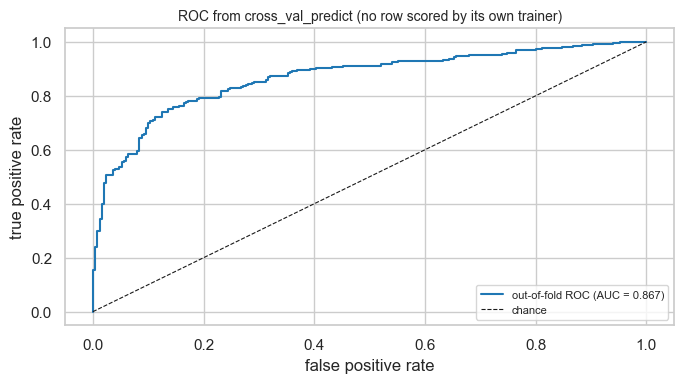

In [27]:
pipe_cv = Pipeline([("s", StandardScaler()), ("m", LogisticRegression(max_iter=1000))])
oof_proba = cross_val_predict(pipe_cv, X6, y6, cv=5, method="predict_proba")[:, 1]
fpr, tpr, _ = roc_curve(y6, oof_proba)
auc_oof = roc_auc_score(y6, oof_proba)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fpr, tpr, color="tab:blue", label=f"out-of-fold ROC (AUC = {auc_oof:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="chance")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC from cross_val_predict (no row scored by its own trainer)", fontsize=10)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


**Section notes — cross validation:**

| Need | Use |
|---|---|
| quick score | `cross_val_score(clf, X, y, cv=5)` |
| train scores + timings + several metrics | `cross_validate(..., return_train_score=True)` |
| imbalanced classification | `StratifiedKFold` / `cv=stratify aware` |
| grouped rows | `GroupKFold(groups=...)` |
| time series | `TimeSeriesSplit` |
| tight error bar | `RepeatedKFold` |
| honest ROC | `cross_val_predict(..., method="predict_proba")` |
| safe preprocessing | everything inside a `Pipeline` |

> **Gotcha:** `cross_val_score(..., cv=5)` with `shuffle=False` on ordered or
> time-series data silently leaks structure. Always choose the splitter that
> matches how your rows are related.

---
## 7. Data leakage

▶ Session #187 – Session on Data Leakage: https://www.youtube.com/watch?v=KHvcr0Q7jSk

**Definition:** *data leakage* = information from outside the training set
(or from the evaluation side of the split) has influenced the model or its
preprocessing. The score goes **up** in the notebook and **down** in
production — the classic "0.95 offline, 0.70 online" mystery.

| Type | What leaks | Typical mistake | Fix |
|---|---|---|---|
| (a) Preprocessing leakage | validation/test statistics | scaler/imputer/PCA fit on all data, then CV or split | fit inside `Pipeline`, after splitting |
| (b) Target leakage | the answer itself, disguised | `days_until_churn`, "total_refunds" recorded after churn | ask: *does this exist at prediction time?* |
| (c) Train-test contamination | duplicated / near-duplicated rows | random split of repeated users or copy-pasted rows | dedupe, group split |
| (d) Time leakage | the future | rolling features over the full series, random split on time data | chronological split, trailing-only features |

### (a) Preprocessing leakage — scaler fitted on train **+ test**

Below, the "deploy batch" arrives on a recalibrated instrument (feature `f0`
has a much larger spread). The **leaky** code fits the scaler on
`train + test`, so the test batch's own statistics are baked into the
transform → the test points stop looking extreme and the score jumps. The
**honest** pipeline fits the scaler on train only and reports what really
happens.

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
n = 600
X7 = rng.normal(0, 1, (n, 5))
y7 = (0.9 * X7[:, 1] + 0.7 * X7[:, 2] + 0.4 * rng.normal(size=n) > 0).astype(int)

n_te = 60
Xtr7, ytr7, Xte7, yte7 = X7[:-n_te], y7[:-n_te], X7[-n_te:].copy(), y7[-n_te:]
Xte7[:, 0] *= 10          # the new batch was measured on a different scale

# WARNING: fitting the scaler on train + test is the classic preprocessing
# leak: the model's statistics already include the rows it is scored on.
# --- LEAKY: the scaler sees the test batch ---
scaler_leaky = StandardScaler().fit(np.vstack([Xtr7, Xte7]))
leaky_model = KNeighborsClassifier(15).fit(scaler_leaky.transform(Xtr7), ytr7)
acc_leaky = leaky_model.score(scaler_leaky.transform(Xte7), yte7)
leaky_cv = cross_val_score(KNeighborsClassifier(15),
                           scaler_leaky.transform(Xtr7), ytr7, cv=5).mean()

# --- HONEST: scaler fitted inside the pipeline on train only ---
honest_pipe = Pipeline([("s", StandardScaler()), ("m", KNeighborsClassifier(15))])
acc_honest = clone(honest_pipe).fit(Xtr7, ytr7).score(Xte7, yte7)
honest_cv = cross_val_score(honest_pipe, Xtr7, ytr7, cv=5).mean()

print(f"holdout accuracy   leaky = {acc_leaky:.3f}   honest = {acc_honest:.3f}")
print(f"CV accuracy (train) leaky = {leaky_cv:.3f}   honest = {honest_cv:.3f}")
print(f"sigma of f0 used by scaler: leaky = {scaler_leaky.scale_[0]:.2f} "
      f"vs train-only = {StandardScaler().fit(Xtr7).scale_[0]:.2f}")
print("-> the leaky scaler absorbed the test batch's spread, flattering the score.")


holdout accuracy   leaky = 0.900   honest = 0.600
CV accuracy (train) leaky = 0.869   honest = 0.856
sigma of f0 used by scaler: leaky = 3.47 vs train-only = 0.99
-> the leaky scaler absorbed the test batch's spread, flattering the score.


### (b) Target leakage — a feature that encodes the outcome

The tell-tale question: **would this feature be knowable at the moment you
make the prediction?** `days_until_contract_end` is tiny *because* churn is
happening — it is the label wearing a disguise.

In [29]:
rng = np.random.default_rng(RANDOM_STATE)
n = 800
base = rng.normal(size=(n, 4))
y8 = (1.1 * base[:, 0] + 0.7 * base[:, 1] + rng.normal(0, 1, n) > 0).astype(int)

df8 = pd.DataFrame(base, columns=["tenure_months", "monthly_spend",
                                  "support_tickets", "usage_ratio"])
df8["churned"] = y8
# the leaky column: written by the churn event itself
df8["days_until_contract_end"] = np.where(
    y8 == 1, rng.integers(0, 15, n), rng.integers(60, 365, n))

print("correlation with the target:")
print(df8.corr()["churned"].round(3).sort_values(ascending=False).to_string())

Xy = df8.drop(columns="churned")
acc_with = cross_val_score(LogisticRegression(max_iter=1000), Xy, y8, cv=5).mean()
acc_without = cross_val_score(LogisticRegression(max_iter=1000),
                              Xy.drop(columns="days_until_contract_end"), y8, cv=5).mean()
print(f"\nCV accuracy WITH  days_until_contract_end : {acc_with:.3f}")
print(f"CV accuracy WITHOUT it                   : {acc_without:.3f}")
print("-> a single leaky column can carry the whole answer. Drop it.")


correlation with the target:
churned                    1.000
tenure_months              0.537
monthly_spend              0.337
usage_ratio                0.021
support_tickets           -0.020
days_until_contract_end   -0.844

CV accuracy WITH  days_until_contract_end : 1.000
CV accuracy WITHOUT it                   : 0.787
-> a single leaky column can carry the whole answer. Drop it.


### (c) Train-test contamination — duplicated rows

A random split can put the **same row** (same user twice, copy-pasted log
entry) on both sides. A flexible model memorises it and scores perfectly on
rows it has literally already seen.

In [30]:
Xc, yc = make_classification(n_samples=600, n_features=8, n_informative=5,
                             random_state=RANDOM_STATE)
Xtrc, Xtec, ytrc, ytec = train_test_split(Xc, yc, test_size=0.3,
                                          random_state=RANDOM_STATE)
n_dup = int(0.4 * len(Xtec))
rng = np.random.default_rng(RANDOM_STATE)
dup_idx = rng.choice(len(Xtrc), n_dup, replace=True)

X_bad = Xtec.copy(); y_bad = ytec.copy()
X_bad[:n_dup] = Xtrc[dup_idx]          # exact copies of training rows
y_bad[:n_dup] = ytrc[dup_idx]

tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtrc, ytrc)
clean_acc = tree.score(Xtec[n_dup:], ytec[n_dup:])
dirty_acc = tree.score(X_bad, y_bad)
print(f"accuracy on untouched test rows : {clean_acc:.3f}")
print(f"accuracy on contaminated test   : {dirty_acc:.3f}   "
      f"({n_dup}/{len(Xtec)} rows were duplicates)")

# dedupe: drop any test row that already exists in train
cols = [f"f{i}" for i in range(Xc.shape[1])]
tr_df = pd.DataFrame(Xtrc, columns=cols); tr_df["y"] = ytrc
te_df = pd.DataFrame(X_bad, columns=cols); te_df["y"] = y_bad
merged = te_df.merge(tr_df.drop_duplicates(), how="left", indicator=True)
dup_mask = merged["_merge"].eq("both").to_numpy()
print(f"duplicate rows detected & dropped : {dup_mask.sum()}")
print(f"accuracy after dedupe             : {tree.score(X_bad[~dup_mask], y_bad[~dup_mask]):.3f}")


accuracy on untouched test rows : 0.833
accuracy on contaminated test   : 0.900   (72/180 rows were duplicates)
duplicate rows detected & dropped : 72
accuracy after dedupe             : 0.833


### (d) Time leakage — features built from the future

Two ways to cheat without noticing:

1. **Feature-level** — a column computed with rows *after* time `t`
   (`shift(-1)`, a centred rolling window, "final" totals). The row looks
   innocent; in production those values do not exist yet.
2. **Split-level** — random CV on ordered data puts *future rows in
   training*, so the model is graded on interpolation it has already seen,
   not on forecasting.

In [31]:
# Two flavours of time leakage, both with a price series
rng = np.random.default_rng(RANDOM_STATE)
price = 100 * np.exp(np.cumsum(rng.normal(0, 0.01, 400)))
df_price = pd.DataFrame({"price": price})
df_price["future_return"] = df_price["price"].shift(-1) / df_price["price"] - 1   # looks at t+1 -> LEAK
df_price["past_return"] = df_price["price"] / df_price["price"].shift(1) - 1       # honest: only t and before
df_price["up_next"] = (df_price["price"].shift(-1) > df_price["price"]).astype(int)  # target: tomorrow's move
df_price = df_price.dropna().reset_index(drop=True)

tscv = TimeSeriesSplit(n_splits=5)
acc_leak = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
                           df_price[["future_return"]], df_price["up_next"], cv=tscv).mean()
acc_ok = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
                         df_price[["past_return"]], df_price["up_next"], cv=tscv).mean()
acc_lr = cross_val_score(LogisticRegression(max_iter=1000),
                         df_price[["past_return"]], df_price["up_next"], cv=tscv).mean()
print(f"LEAKY feature  (return from t to t+1) : accuracy {acc_leak:.3f}")
print(f"honest feature (return up to t)       : accuracy {acc_ok:.3f} (tree) / {acc_lr:.3f} (logit)")
print("-> tomorrow's return IS the label. A chronological CV does not save you:")
print("   the feature itself must not exist before the prediction moment.\n")

# Same data shape, second flavour: the SPLIT leaks the future.
t_idx = np.arange(300)
y_ts = 100 + 0.05 * t_idx + 3 * np.sin(t_idx / 10) + np.random.default_rng(RANDOM_STATE).normal(0, 3, 300)
X_ts = t_idx.reshape(-1, 1)


def mae(model, train_idx, test_idx):
    model = clone(model).fit(X_ts[train_idx], y_ts[train_idx])
    return float(np.mean(np.abs(y_ts[test_idx] - model.predict(X_ts[test_idx]))))


rand_tr, rand_te = train_test_split(np.arange(300), test_size=0.2,
                                    random_state=RANDOM_STATE)
tree = DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
mae_rand = mae(tree, rand_tr, rand_te)
mae_time = float(np.mean([mae(tree, tr, te)
                          for tr, te in TimeSeriesSplit(n_splits=4).split(X_ts)]))
mae_lin = float(np.mean([mae(LinearRegression(), tr, te)
                         for tr, te in TimeSeriesSplit(n_splits=4).split(X_ts)]))
print("trended series, target = next value, model must use the time index")
print(f"  tree  random split  MAE = {mae_rand:.3f}   (test rows are bracketed by train rows)")
print(f"  tree  time split    MAE = {mae_time:.3f}   (must EXTRAPOLATE -> much worse)")
print(f"  linear time split   MAE = {mae_lin:.3f}   (simple models extrapolate better)")
print("-> random CV on temporal data measures interpolation into the past, not forecasting.")


LEAKY feature  (return from t to t+1) : accuracy 0.991
honest feature (return up to t)       : accuracy 0.536 (tree) / 0.470 (logit)
-> tomorrow's return IS the label. A chronological CV does not save you:
   the feature itself must not exist before the prediction moment.

trended series, target = next value, model must use the time index
  tree  random split  MAE = 2.784   (test rows are bracketed by train rows)
  tree  time split    MAE = 4.378   (must EXTRAPOLATE -> much worse)
  linear time split   MAE = 3.762   (simple models extrapolate better)
-> random CV on temporal data measures interpolation into the past, not forecasting.


### Detection checklist

- [ ] Did I split **before** any `.fit()` — scaler, imputer, encoder, PCA,
      selector, feature engineering?
- [ ] Does every column exist at **prediction time**? (ask per feature)
- [ ] Could any row appear on **both sides** of the split (dupes, groups,
      same user/session)?
- [ ] Is the data **time-ordered**, and does my split respect the arrow of
      time?
- [ ] Is my CV score **wildly better** than the leaderboard/production
      number? (classic symptom)
- [ ] Would a **domain expert** believe this feature (e.g. a 0.99 AUC from
      three features)?

### Prevention rules

1. `train_test_split` (or your CV) happens **first** — before any fit.
2. Put *every* learned transform in a `Pipeline` / `ColumnTransformer` so it
   can only ever see the training fold.
3. Timestamped data → chronological splits + trailing-only features.
4. Repeated entities → keep a `groups=` vector and use `GroupKFold`.
5. Deduplicate before splitting.
6. Compute features with `fit`-able, past-only logic; never with aggregates
   over the whole frame.

### The weapons: `Pipeline` + `ColumnTransformer`

In [32]:
rng = np.random.default_rng(RANDOM_STATE)
dfw = pd.DataFrame({
    "age": rng.normal(35, 10, 400).round(0),
    "income": rng.lognormal(10.5, 0.6, 400).round(0),
    "city": rng.choice(["delhi", "mumbai", "pune"], 400),
    "plan": rng.choice(["free", "pro", "enterprise"], 400, p=[0.6, 0.3, 0.1]),
})
dfw.loc[rng.random(400) < 0.08, "income"] = np.nan          # missing values
income_median = dfw["income"].median()                      # pandas skips NaN, np.median would return NaN
# noisy target built from two real drivers (so the demo is not trivially 100%)
signal = (0.06 * (dfw["age"] - 35)
          + 0.6 * (np.log(dfw["income"].fillna(income_median)) - 10.5))
yw = (signal + rng.normal(0, 1, 400) > 0).astype(int)
print("target balance:", np.bincount(yw), "\n")

numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler())])
categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                  sparse_output=False))])

preprocess = ColumnTransformer(
    [("num", numeric, ["age", "income"]),
     ("cat", categorical, ["city", "plan"])],
    remainder="drop", sparse_threshold=0.0)

leak_safe = Pipeline([("pre", preprocess), ("clf", LogisticRegression(max_iter=1000))])

# the split happens FIRST, and the whole pipeline is re-fit per fold
Xtrw, Xtew, ytrw, ytew = train_test_split(dfw, yw, test_size=0.25,
                                          random_state=RANDOM_STATE, stratify=yw)
leak_safe.fit(Xtrw, ytrw)
print("holdout accuracy :", round(leak_safe.score(Xtew, ytew), 3))
print("transformed shape:", leak_safe.named_steps["pre"].transform(Xtrw).shape)
print("feature names    :", list(leak_safe.named_steps["pre"].get_feature_names_out()))
print("CV score         :",
      f"{cross_val_score(leak_safe, dfw, yw, cv=5).mean():.3f}")


target balance: [221 179] 



holdout accuracy : 0.77


transformed shape: (300, 8)
feature names    : ['num__age', 'num__income', 'cat__city_delhi', 'cat__city_mumbai', 'cat__city_pune', 'cat__plan_enterprise', 'cat__plan_free', 'cat__plan_pro']


CV score         : 0.713


**Section notes — leakage:**

| Type | Fast test | Fix |
|---|---|---|
| preprocessing | was anything `fit` on all data? | `Pipeline` after split |
| target | does it exist at prediction time? | delete the column |
| contamination | `df.duplicated()` across splits | dedupe / `GroupKFold` |
| time | `max(train_date) < min(test_date)`? | `TimeSeriesSplit`, trailing windows |

> **Gotcha:** leakage rarely throws an error — it shows up as a number that
> is **too good**. If a result surprises you, assume leakage first, bugs
> second.

---
## 8. Hyperparameter tuning

▶ Session #188 – Session on Hyperparameter Tuning: https://www.youtube.com/watch?v=cDmMVCC4dEE

| | Hyperparameter | Parameter |
|---|---|---|
| set by | **you**, before training | **learned from data** during `.fit()` |
| examples | `C`, `max_depth`, `n_estimators`, `n_components`, KNN's `k` | regression coefficients, support vectors, PCA components, centroids |
| searched by | `GridSearchCV` / `RandomizedSearchCV` | SGD, eigendecomposition, EM, … |
| controlled after fit? | only by re-fitting | yes (`.coef_`, `.components_`) |

Tuning = trying candidate hyperparameters and scoring each one **with
cross-validation**, never with the holdout set (the holdout is spent once,
at the very end).

### `GridSearchCV(estimator, param_grid, cv=None, scoring=None, refit=True, ...)`
**What it does:** exhaustively fits the estimator for every parameter
combination, evaluates each with CV, then refits the best combination on
the whole provided data.
**Parameters:**
- `estimator` — estimator **or Pipeline** — object to tune
- `param_grid` — dict / list of dicts — `{param_name: [values...]}` (a *list*
  of dicts lets you give different grids to different estimators)
- `cv` — int / CV splitter — cross-validation strategy — default `5`
- `scoring` — str / callable — metric to optimise — default: estimator's `.score`
- `refit` — bool/str — after searching, refit the best estimator on all data
  so you can call `.predict()` directly — default `True`
- `n_jobs` — int — parallel fits — default `1`
- `return_train_score` — bool — keep fold train scores (slower, diagnostic)
**Attributes:** `best_params_`, `best_score_`, `best_estimator_`, `cv_results_`
**Returns:** the fitted search object (itself an estimator)

In [33]:
Xh, yh = make_classification(n_samples=600, n_features=10, n_informative=6,
                             n_redundant=2, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {"n_estimators": [50, 100, 200],
              "max_depth": [3, 6, None],
              "min_samples_leaf": [1, 3]}
n_combos = 3 * 3 * 2

# WARNING: the grid is scored with inner CV only. The final holdout set is
# touched exactly once, after every choice (k, imputer, C, ...) is frozen.
t0 = time.perf_counter()
gs = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                  param_grid, cv=inner_cv, scoring="accuracy", refit=True)
gs.fit(Xh, yh)
elapsed = time.perf_counter() - t0

print(f"grid size            : {n_combos} combos x 5 folds = {n_combos * 5} fits")
print("best_params_         :", gs.best_params_)
print("best_score_ (CV mean) :", round(gs.best_score_, 4))
print(f"wall time            : {elapsed:.2f}s")

cvres = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score",
                                      "std_test_score", "rank_test_score",
                                      "mean_fit_time"]]
print(cvres.sort_values("rank_test_score").head(5).round(4).to_string(index=False))


grid size            : 18 combos x 5 folds = 90 fits
best_params_         : {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
best_score_ (CV mean) : 0.8967
wall time            : 6.35s
                                                         params  mean_test_score  std_test_score  rank_test_score  mean_fit_time
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}           0.8967          0.0282                1         0.1332
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}           0.8967          0.0306                1         0.0646
{'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}           0.8967          0.0449                1         0.0617
 {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 50}           0.8950          0.0482                4         0.0326
{'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}           0.8900          0.0467                5         0.1231


### `RandomizedSearchCV(estimator, param_distributions, n_iter=10, ...)`
**What it does:** samples `n_iter` **random** combinations from the given
distributions instead of enumerating them.
**Parameters (extras vs GridSearch):**
- `param_distributions` — dict — values are **distributions**: `randint(a, b)`,
  `loguniform(a, b)`, `choice([...])`, or lists (sampled uniformly)
- `n_iter` — int — number of parameter settings to try — default `10`
**When preferable:**
- the space is **large** (≥ 10³ combos — grid search never finishes)
- some parameters matter far more than others → random sampling explores
  the important ones at *every* resolution, grid search does not
- you want to switch from coarse to fine by shrinking the distributions

> **TIP:** on a log-scale parameter like `C ∈ [1e-3, 1e3]`, uniform grid
> sampling wastes almost all points near the middle — use `loguniform`.

In [34]:
dists = {"n_estimators": randint(20, 300),
         "max_depth": randint(2, 12),
         "min_samples_leaf": randint(1, 11),
         "max_features": loguniform(0.1, 1.0)}

t0 = time.perf_counter()
rs = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                        dists, n_iter=15, cv=3, scoring="accuracy",
                        random_state=RANDOM_STATE, refit=True)
rs.fit(Xh, yh)
elapsed = time.perf_counter() - t0

print("best_params_         :", {k: round(float(v), 3) if isinstance(v, (float, np.floating)) else v
                                 for k, v in rs.best_params_.items()})
print("best_score_ (CV mean) :", round(rs.best_score_, 4))
print(f"wall time            : {elapsed:.2f}s  (15 samples x 3 folds)")


best_params_         : {'max_depth': 7, 'max_features': 0.161, 'min_samples_leaf': 4, 'n_estimators': 210}
best_score_ (CV mean) : 0.8633
wall time            : 4.17s  (15 samples x 3 folds)


### Search cost — small grid vs random search (same fit budget)

Both cells below pay for **27 model fits**; they just spend the budget
differently: a 3×3 lattice vs 9 random draws from continuous distributions.

In [35]:
small_grid = {"n_estimators": [50, 100, 200], "max_depth": [3, 6, 9]}

t0 = time.perf_counter()
grid_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                           small_grid, cv=3, scoring="accuracy")
grid_search.fit(Xh, yh)
t_grid = time.perf_counter() - t0

t0 = time.perf_counter()
random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(50, 201), "max_depth": randint(3, 10)},
    n_iter=9, cv=3, scoring="accuracy", random_state=RANDOM_STATE)
random_search.fit(Xh, yh)
t_random = time.perf_counter() - t0

cost_tbl = pd.DataFrame([
    {"search": "GridSearchCV (3x3 lattice)", "fits": 9 * 3, "seconds": t_grid,
     "best_cv": grid_search.best_score_},
    {"search": "RandomizedSearchCV (9 draws)", "fits": 9 * 3, "seconds": t_random,
     "best_cv": random_search.best_score_},
])
print(cost_tbl.round(4).to_string(index=False))
print("\nSame budget and same parameter ranges, different coverage:")
print("the grid is locked to 3 values per dimension (and misses everything in")
print("between), while random search explores the full range of each parameter.")


                      search  fits  seconds  best_cv
  GridSearchCV (3x3 lattice)    27   1.7694   0.8833
RandomizedSearchCV (9 draws)    27   2.1947   0.8767

Same budget and same parameter ranges, different coverage:
the grid is locked to 3 values per dimension (and misses everything in
between), while random search explores the full range of each parameter.


### The correct pattern — `Pipeline` + `GridSearchCV` (one grid, every step)

Hyperparameters of **preprocessing** (`pca__n_components`) and of the
**model** (`clf__C`) live in one grid, and the whole pipeline is re-fit per
fold — so nothing leaks (§6/§7) and you tune everything at once.

In [36]:
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=0.25,
                                              random_state=RANDOM_STATE, stratify=yh)

pipe_tune = Pipeline([("scale", StandardScaler()),
                      ("pca", PCA()),
                      ("clf", LogisticRegression(max_iter=2000))])

grid_tune = {"pca__n_components": [2, 4, 6, 8],
             "clf__C": [0.01, 0.1, 1.0, 10.0]}

gs_pipe = GridSearchCV(pipe_tune, grid_tune, cv=5, scoring="accuracy",
                       return_train_score=True, refit=True)
gs_pipe.fit(Xh_tr, yh_tr)

res_tune = pd.DataFrame(gs_pipe.cv_results_)
res_tune["gap"] = res_tune["mean_train_score"] - res_tune["mean_test_score"]
print("best_params_  :", gs_pipe.best_params_)
print(f"best CV score : {gs_pipe.best_score_:.3f}")
print(f"holdout score : {gs_pipe.score(Xh_te, yh_te):.3f}")
print(res_tune.sort_values("rank_test_score")[["params", "mean_train_score",
                                               "mean_test_score", "gap"]]
      .head(5).round(4).to_string(index=False))


best_params_  : {'clf__C': 0.1, 'pca__n_components': 8}
best CV score : 0.820
holdout score : 0.880
                                  params  mean_train_score  mean_test_score    gap
 {'clf__C': 0.1, 'pca__n_components': 8}            0.8372           0.8200 0.0172
 {'clf__C': 1.0, 'pca__n_components': 8}            0.8317           0.8156 0.0161
{'clf__C': 10.0, 'pca__n_components': 8}            0.8306           0.8156 0.0150
{'clf__C': 0.01, 'pca__n_components': 8}            0.8250           0.8133 0.0117
{'clf__C': 0.01, 'pca__n_components': 6}            0.8028           0.8000 0.0028


### Nested CV — the honest estimate *after* tuning

If you tune on the same CV folds you then quote, the reported score is
**optimistic** (you picked the model that got lucky on those folds).
Nested CV wraps an inner search inside an outer CV:

```text
outer fold i  ┌ inner CV on train_i  -> pick best hyperparams
              └ evaluate that choice on held-out test_i  -> score_i
CV score = mean(score_i)      <- unbiased for the *whole procedure*
```

In [37]:
outer_cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
inner_cv3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

base_pipe = Pipeline([("scale", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=2000))])
inner_search = GridSearchCV(base_pipe,
                            {"clf__C": [0.01, 0.1, 1.0, 10.0]}, cv=inner_cv3)

plain = cross_validate(clone(base_pipe), Xh, yh, cv=outer_cv, scoring="accuracy")
nested = cross_validate(inner_search, Xh, yh, cv=outer_cv,
                        scoring="accuracy", return_train_score=True)

print(f"plain outer CV (C fixed at 1) : {plain['test_score'].mean():.3f} "
      f"± {plain['test_score'].std():.3f}")
print(f"nested CV (C tuned in-fold)   : {nested['test_score'].mean():.3f} "
      f"± {nested['test_score'].std():.3f}")
print("outer train scores            :", nested["train_score"].round(3))
print("Cost: outer(5) x inner(3) x 4 Cs + refits — only run nested CV when")
print("you need an honest number for a paper/report, not during exploration.")


plain outer CV (C fixed at 1) : 0.822 ± 0.043
nested CV (C tuned in-fold)   : 0.828 ± 0.037
outer train scores            : [0.833 0.827 0.827 0.829 0.854]
Cost: outer(5) x inner(3) x 4 Cs + refits — only run nested CV when
you need an honest number for a paper/report, not during exploration.


### Choosing the metric — `scoring`, `make_scorer`

`scoring` accepts a name (`"accuracy"`, `"f1"`, `"roc_auc"`, `"neg_mean_squared_error"`)
or a callable built with `make_scorer`. **Optimise the metric you will be
judged on**, not the default `.score()`:

| Situation | scoring |
|---|---|
| balanced classes, equal costs | `accuracy` |
| imbalance, positive class matters | `f1`, `precision`, `recall` |
| ranking / probability quality | `roc_auc` (binary), `average_precision` |
| regression, penalise big misses | `neg_mean_squared_error` / `neg_mean_absolute_error` |
| your own rule | `make_scorer(my_fn, greater_is_better=True, pos_label=1)` |

In [38]:
Xb, yb = make_classification(n_samples=800, n_features=10, n_informative=6,
                             weights=[0.95, 0.05], flip_y=0.02,
                             random_state=RANDOM_STATE)
rows = []
for scoring in ["accuracy", "f1", "roc_auc"]:
    s = cross_val_score(LogisticRegression(max_iter=1000), Xb, yb, cv=5, scoring=scoring)
    rows.append({"scoring": scoring, "mean": s.mean(), "std": s.std()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\naccuracy looks great (it just predicts the 95% majority class) —")
print("f1 / roc_auc expose that the minority class is barely detected.")

custom_f1 = make_scorer(f1_score, pos_label=1)
print("make_scorer(f1_score) ->",
      round(cross_val_score(LogisticRegression(max_iter=1000), Xb, yb,
                            cv=5, scoring=custom_f1).mean(), 3))


 scoring  mean   std
accuracy 0.936 0.005
      f1 0.064 0.079
 roc_auc 0.760 0.172

accuracy looks great (it just predicts the 95% majority class) —
f1 / roc_auc expose that the minority class is barely detected.
make_scorer(f1_score) -> 0.064


### Grids worth trying per model (sklearn-only)

| Model | Parameter grid |
|---|---|
| `LogisticRegression` | `C: loguniform(1e-3, 1e3)`, `penalty: ["l1","l2"]` with `solver="saga"` |
| `RandomForestClassifier` | `n_estimators: [100, 300, 600]`, `max_depth: [None, 6, 12, 20]`, `min_samples_leaf: [1, 2, 4]`, `max_features: ["sqrt", 0.3, 0.7]` |
| `SVC` | `C: loguniform(1e-2, 1e3)`, `gamma: loguniform(1e-4, 1e-1)`, `kernel: ["rbf", "linear"]` |
| `KNeighborsClassifier` | `n_neighbors: [3, 5, 11, 21]`, `weights: ["uniform","distance"]`, `p: [1, 2]` |
| `GradientBoosting*` | `n_estimators: [100, 300]`, `learning_rate: loguniform(1e-2, 0.3)`, `max_depth: [2, 4, 6]` |
| `PCA` in a pipeline | `n_components: [0.8, 0.9, 0.95]` or `[2, 5, 10, 20]` |

**Practical tuning tips**

1. **Coarse → fine.** Random search on wide ranges first, then a small grid
   around the winner.
2. **Log scale for scale parameters** (`C`, `gamma`, `learning_rate`,
   `alpha`) — equal *ratios*, not equal differences.
3. **Leave the holdout alone.** Tune on CV inside the training set; touch
   the test set once (§11).
4. **Watch the train–test gap** in `cv_results_`: a large gap means the
   model needs regularisation/capacity control, not a finer grid.
5. **Don't over-tune.** Choosing the best of 500 noisy candidates on 5 folds
   selects for *fold luck*. Fewer, sensible candidates + nested CV when it
   matters.
6. Fix `random_state` everywhere so a rerun reproduces the same winner.

**Section notes — tuning:**

| Tool | Use for |
|---|---|
| `GridSearchCV` | small, curated grids you want exhausted |
| `RandomizedSearchCV` | big/continuous spaces, `n_iter` budget |
| `best_params_ / best_score_` | the winner and its CV mean |
| `pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")` | the full leaderboard |
| nested CV | an honest score for the whole tuned procedure |
| `scoring="f1"/"roc_auc"` | imbalanced problems |

> **Gotcha:** `best_score_` is the CV mean of the **best candidate** — it is
> optimistically biased. Never report it as your final test performance.

---
## 9. Feature engineering — missing values, deep dive

▶ Session #199 – Feature Engineering | Handling Missing Values Part 1: https://www.youtube.com/watch?v=e1-5NOwWCmo

| Strategy | Code | Keep when | Loses when |
|---|---|---|---|
| **Drop rows** | `df.dropna()` | missing completely at random *and* you have plenty of rows | you shrink/bias the sample, or test rows also have NaN |
| **Statistical impute** | `SimpleImputer(strategy="mean"/"median"/"most_frequent")` | simple, fast, safe baseline | distorts distributions & relationships (variance shrinks) |
| **Add indicator** | `SimpleImputer(add_indicator=True)` | *missingness itself is informative* (e.g. "no salary entered") | adds columns → slight overfit risk |
| **Model impute** | `KNNImputer`, `IterativeImputer` | relationships between features can reconstruct the value | slower, can overfit, must still be fit on train only |
| **Drop column** | `df.drop(columns=[...])` | >~60% missing or no domain justification | you may delete a strong-but-sparse signal |

> **Golden rule:** the imputer is a *model* — `fit` it on the **training
> fold only** (inside a `Pipeline`), or the fold's own values leak back in.

missing % per column
f0    12.0
f1    12.2
f2    13.2
f3    11.3
f4    12.5
f5    12.8
rows with at least one NaN: 324 / 600


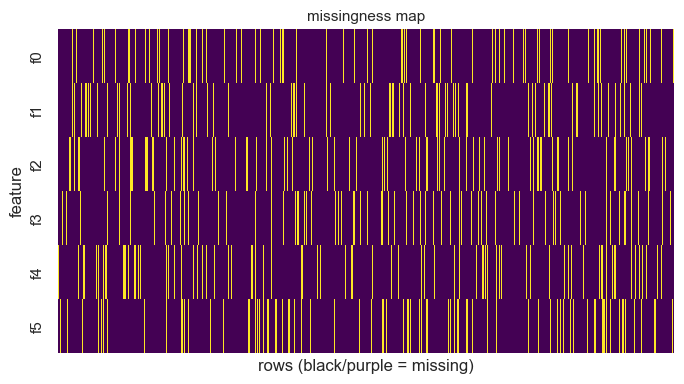

In [39]:
Xi9, yi9 = make_classification(n_samples=600, n_features=6, n_informative=4,
                               n_redundant=1, random_state=RANDOM_STATE)
df9 = pd.DataFrame(Xi9, columns=[f"f{i}" for i in range(6)])
rng9 = np.random.default_rng(RANDOM_STATE)
df9_m = df9.mask(rng9.random(df9.shape) < 0.12)          # ~12% MCAR

print("missing % per column")
print((df9_m.isna().mean() * 100).round(1).to_string())
print("rows with at least one NaN:", int(df9_m.isna().any(axis=1).sum()), "/", len(df9_m))

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(df9_m.isna().T, cbar=False, cmap="viridis", ax=ax,
            xticklabels=False)
ax.set_yticklabels(df9_m.columns)
ax.set_ylabel("feature"); ax.set_xlabel("rows (black/purple = missing)")
ax.set_title("missingness map", fontsize=11)
plt.tight_layout()
plt.show()


### `SimpleImputer(strategy="mean", add_indicator=True)`
**What it does:** replaces NaNs with a per-column statistic and appends one
0/1 column per feature that had missing values at `fit` time.
**Parameters:**
- `strategy` — `"mean" | "median" | "most_frequent" | "constant"` — default `"mean"`
- `add_indicator` — bool — add "was missing" indicator columns — default `False`
- `missing_values` — value treated as missing — default `np.nan`
**Returns:** transformed array (`.indicator_` holds the added columns)

In [40]:
# TIP: switch to strategy="median" when the column is skewed — the mean is
# dragged around by a few large values (skew demo in §10).
imp9 = SimpleImputer(strategy="mean", add_indicator=True)
Z_ind = imp9.fit_transform(df9_m)
print("shape:", df9_m.shape, "->", Z_ind.shape)
print("columns imputed   :", imp9.statistics_.round(3))
print("indicator features:", imp9.indicator_.features_)


shape: (600, 6) -> (600, 12)
columns imputed   : [-0.524  0.53   0.046 -0.091 -0.035 -0.511]
indicator features: [0 1 2 3 4 5]


### `KNNImputer(n_neighbors=5, weights="uniform")`
**What it does:** fills a NaN using the **mean of the k nearest training
rows** (distance computed on the columns both rows share).
**Parameters:**
- `n_neighbors` — int — neighbours to average — default `5`
- `weights` — `"uniform" | "distance"` — equal or distance-weighted
- `missing_values` — default `np.nan`
**Returns:** imputed array with the same shape as the input

### `IterativeImputer` (experimental)
Treats each feature as a target regressed on the others (round-robin,
like MICE). More faithful than a column mean, but **experimental** — it
needs `from sklearn.experimental import enable_iterative_imputer` and can be
slow. Use it when features are strongly inter-correlated.

In [41]:
knn9 = KNNImputer(n_neighbors=5, weights="distance")
Z_knn = knn9.fit_transform(df9_m)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    it9 = IterativeImputer(random_state=RANDOM_STATE, max_iter=5)
    Z_it = it9.fit_transform(df9_m)

row = int(np.flatnonzero(df9_m.isna().to_numpy().any(axis=1))[0])
print(f"row {row}  original :", np.round(df9_m.to_numpy()[row], 3))
print(f"       mean-imputed :", np.round(imp9.transform(df9_m)[row, :6], 3))
print(f"          KNN-imputed:", np.round(Z_knn[row], 3))
print(f"   Iterative-imputed:", np.round(Z_it[row], 3))
print("KNN/Iterative keep the row's *relationships* instead of collapsing to one mean.")


row 0  original : [-1.166  2.452 -0.254  1.381    nan -1.264]
       mean-imputed : [-1.166  2.452 -0.254  1.381 -0.035 -1.264]
          KNN-imputed: [-1.166  2.452 -0.254  1.381  0.662 -1.264]
   Iterative-imputed: [-1.166  2.452 -0.254  1.381  0.601 -1.264]
KNN/Iterative keep the row's *relationships* instead of collapsing to one mean.


### Impact experiment — drop vs mean vs KNN vs mean+indicator

Same data, same CV folds, four strategies. Any `fit` happens inside the
pipeline, per fold (leakage-safe).

In [42]:
keep = ~df9_m.isna().any(axis=1)
acc_drop = cross_val_score(LogisticRegression(max_iter=1000),
                           df9_m.to_numpy()[keep], yi9[keep], cv=5).mean()

def make_pipe(imputer):
    return Pipeline([("imp", imputer),
                     ("clf", LogisticRegression(max_iter=1000))])

acc_mean = cross_val_score(make_pipe(SimpleImputer(strategy="mean")),
                           df9_m, yi9, cv=5).mean()
acc_ind = cross_val_score(make_pipe(SimpleImputer(strategy="mean", add_indicator=True)),
                          df9_m, yi9, cv=5).mean()
acc_knn = cross_val_score(make_pipe(KNNImputer(n_neighbors=5)),
                          df9_m, yi9, cv=5).mean()

impact_tbl = pd.DataFrame([
    {"strategy": "drop rows with NaN", "rows_used": int(keep.sum()),
     "extra_features": 0, "cv_accuracy": acc_drop},
    {"strategy": "mean impute", "rows_used": len(df9_m),
     "extra_features": 0, "cv_accuracy": acc_mean},
    {"strategy": "mean impute + indicator", "rows_used": len(df9_m),
     "extra_features": int(df9_m.isna().any(axis=0).sum()), "cv_accuracy": acc_ind},
    {"strategy": "KNN impute (k=5)", "rows_used": len(df9_m),
     "extra_features": 0, "cv_accuracy": acc_knn},
])
print(impact_tbl.round(3).to_string(index=False))
print(f"\ndropping rows cost you {len(df9_m) - int(keep.sum())} samples "
      f"({(1 - keep.mean()) * 100:.1f}% of the data)")


               strategy  rows_used  extra_features  cv_accuracy
     drop rows with NaN        276               0        0.699
            mean impute        600               0        0.678
mean impute + indicator        600               6        0.673
       KNN impute (k=5)        600               0        0.673

dropping rows cost you 324 samples (54.0% of the data)


### When to drop a **column**

| % missing | Verdict |
|---|---|
| < 5% | impute with mean/median — barely a decision |
| 5–30% | impute (+ indicator if missingness is informative); check CV |
| 30–60% | keep only if the feature is domain-critical or the missingness is meaningful |
| > 60–70% | usually drop — you are mostly modelling your own imputer |

Also drop when: the column is a **post-outcome** artifact (leakage, §7b), is
duplicated by other columns, or is constant/near-constant.

In [43]:
df9b = df9_m.copy()
df9b.loc[df9b.sample(frac=0.55, random_state=RANDOM_STATE).index, "f5"] = np.nan
pct = (df9b.isna().mean() * 100).round(1)
print("missing % after injecting extra missingness into f5:")
print(pct.to_string())
print("f5 ->", f"DROP ({pct['f5']:.1f}% of rows have no value)" if pct["f5"] > 60 else "keep / impute")


missing % after injecting extra missingness into f5:
f0    12.0
f1    12.2
f2    13.2
f3    11.3
f4    12.5
f5    60.8
f5 -> DROP (60.8% of rows have no value)


**Section notes — missing values:**

| Question | Answer |
|---|---|
| quick fix | `SimpleImputer(strategy="median")` inside a pipeline |
| missingness informative | `SimpleImputer(add_indicator=True)` |
| correlated features | `KNNImputer(k)` / `IterativeImputer` |
| drop rows? | only if losses are small and MCAR |
| drop column? | >60% missing, or leaky/duplicated |
| fit where? | **inside the pipeline, on the training fold only** |

> **Gotcha:** imputing with the full-data mean before splitting is leakage
> (§7a) — the validation fold helped choose the value that replaced its own
> NaNs.

---
## 10. Feature engineering — transformations & encoding

### Why transform?

| Problem | Symptom | Remedy |
|---|---|---|
| skewed numeric feature | heavy right tail, mean >> median, hurts linear models & distance metrics | `log1p`, `sqrt`, **Box-Cox**, **Yeo-Johnson** |
| different scales | one feature dominates PCA / SVM / KNN / regularised linear models | scaler (below) |
| categorical feature | models only read numbers | one-hot / ordinal / target / frequency encoding |

**Skewness: `skew()` → 0 is the goal** (linear models and distance-based
methods behave best on roughly symmetric inputs).

transform                   skew          min          max
raw                        2.974      1961.12    461890.41
log1p                     -0.048         7.58        13.04
sqrt                       1.235        44.28       679.63
boxcox (λ=0.02)            0.000         8.18        14.89
yeo-johnson                0.000        -3.49         3.31


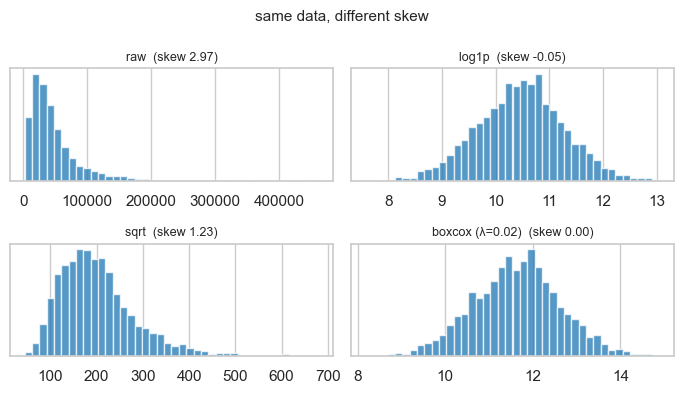

In [44]:
rng = np.random.default_rng(RANDOM_STATE)
income = rng.lognormal(mean=10.5, sigma=0.8, size=2000)

box, lam = boxcox(income)                                  # requires strictly positive data
yeo = PowerTransformer(method="yeo-johnson").fit_transform(
    income.reshape(-1, 1)).ravel()                         # handles zeros/negatives too

variants = {"raw": income, "log1p": np.log1p(income),
            "sqrt": np.sqrt(income), f"boxcox (λ={lam:.2f})": box,
            "yeo-johnson": yeo}
print(f"{'transform':22s} {'skew':>9s} {'min':>12s} {'max':>12s}")
for name, v in variants.items():
    print(f"{name:22s} {skew(v):9.3f} {v.min():12.2f} {v.max():12.2f}")

fig, axes = plt.subplots(2, 2, figsize=(7, 4))
for ax, (name, v) in zip(axes.flat, list(variants.items())[:4]):
    ax.hist(v, bins=40, color="tab:blue", alpha=0.75)
    ax.set_title(f"{name}  (skew {skew(v):.2f})", fontsize=9)
    ax.set_yticks([])
fig.suptitle("same data, different skew", fontsize=11)
plt.tight_layout()
plt.show()


### Scalers — formulas and when to use each

| Scaler | Formula | Range / property | Use when |
|---|---|---|---|
| `StandardScaler` | `(x - μ) / σ` | mean 0, std 1, **unbounded** | default; roughly Gaussian features, no big outliers |
| `MinMaxScaler` | `(x - min) / (max - min)` | exactly **[0, 1]** | bounded inputs needed (images, neural nets, **no** outliers) |
| `RobustScaler` | `(x - median) / IQR` | unbounded, **outlier-proof** | heavy tails / known outliers |
| `MaxAbsScaler` | `x / max\|x\|` | **[-1, 1]**, keeps sparsity | **sparse** matrices (TF-IDF) — zeros stay zeros |

Sensitivity demo — one feature with 5 extreme outliers:

In [45]:
rng = np.random.default_rng(RANDOM_STATE)
n = 400
age = rng.normal(35, 10, n)
salary = rng.lognormal(11.0, 0.5, n)
salary[:5] *= 8                                   # 5 extreme outliers
X_scalers = np.column_stack([age, salary])
is_inlier = np.ones(n, dtype=bool)
is_inlier[:5] = False

# For each scaler: fit on ALL rows (outliers included) and on the clean rows
# only, then look at where the normal points end up. A robust scaler's
# parameters barely move when outliers arrive; a mean/std one's do.
rows = []
for name, sc in [("StandardScaler", StandardScaler()),
                 ("MinMaxScaler", MinMaxScaler()),
                 ("RobustScaler", RobustScaler()),
                 ("MaxAbsScaler", MaxAbsScaler())]:
    Z_with = clone(sc).fit(X_scalers).transform(X_scalers)
    Z_without = clone(sc).fit(X_scalers[is_inlier]).transform(X_scalers[is_inlier])
    std_with = Z_with[is_inlier, 1].std()
    std_without = Z_without[:, 1].std()
    rows.append({"scaler": name,
                 "outlier lands at": Z_with[:, 1].max(),
                 "inlier spread, fit WITH outliers": std_with,
                 "inlier spread, fit WITHOUT outliers": std_without,
                 "spread shifted by": abs(std_with / std_without - 1) * 100})

scaler_tbl = pd.DataFrame(rows)
print(scaler_tbl.round(3).to_string(index=False))
print("\n-> 'fit WITHOUT outliers' is the scaler's ideal behaviour. The last")
print("   column says how far the 5 outliers dragged every *normal* point away")
print("   from it: RobustScaler 0.5%, the others 46-71%.")
print("-> RobustScaler still puts the outlier far out — correct, it IS extreme.")


        scaler  outlier lands at  inlier spread, fit WITH outliers  inlier spread, fit WITHOUT outliers  spread shifted by
StandardScaler            10.082                             0.540                                1.000             46.012
  MinMaxScaler             1.000                             0.049                                0.169             70.941
  RobustScaler            15.755                             0.827                                0.831              0.483
  MaxAbsScaler             1.000                             0.048                                0.159             69.604

-> 'fit WITHOUT outliers' is the scaler's ideal behaviour. The last
   column says how far the 5 outliers dragged every *normal* point away
   from it: RobustScaler 0.5%, the others 46-71%.
-> RobustScaler still puts the outlier far out — correct, it IS extreme.


### Encoding categorical features

| Encoder | Output | Use when | Watch out |
|---|---|---|---|
| `OneHotEncoder` | one binary column per category | nominal (no order), default choice | cardinality explosion (zip codes) |
| `OrdinalEncoder` | single integer column | **ordered** categories (small < medium < large) | model may read false numeric distance |
| target encoding | mean of target per category | high-cardinality nominal features | **leaks the target** — must be computed inside CV folds only, with smoothing |
| frequency encoding | count/proportion per category | category *popularity* carries signal | ties, rare categories, also fold-wise for safety |

In [46]:
df10 = pd.DataFrame({
    "city": ["delhi", "mumbai", "pune", "delhi", "mumbai", "delhi",
             "bangalore", "pune", "mumbai", "delhi"],
    "day": ["Mon", "Tue", "Wed", "Thu", "Fri", "Mon", "Tue", "Wed", "Thu", "Fri"],
})

# NOTE: handle_unknown="ignore" lets the encoder swallow a city it never saw
# at fit time (all-zero row) instead of raising — see the mismatch demo below.
# --- OneHotEncoder ---
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
M = ohe.fit_transform(df10[["city"]])
print("OneHotEncoder ->", M.shape, "| categories:", ohe.categories_[0])
print("feature names :", list(ohe.get_feature_names_out()))
print(M[:3].astype(int))

sparse_M = OneHotEncoder().fit_transform(df10[["city"]])   # sparse_output=True default
print("default output is sparse:", type(sparse_M).__name__, sparse_M.shape)

# --- OrdinalEncoder (categories have a real order) ---
ode = OrdinalEncoder(categories=[["Mon", "Tue", "Wed", "Thu", "Fri"]])
print("\nOrdinalEncoder(day) ->", ode.fit_transform(df10[["day"]]).ravel())

# --- frequency encoding ---
freq = df10["city"].value_counts(normalize=True)
print("\nfrequency encoding:")
print(df10.assign(city_freq=df10["city"].map(freq)).head(6).to_string(index=False))


OneHotEncoder -> (10, 4) | categories: ['bangalore' 'delhi' 'mumbai' 'pune']
feature names : ['city_bangalore', 'city_delhi', 'city_mumbai', 'city_pune']
[[0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
default output is sparse: csr_matrix (10, 4)

OrdinalEncoder(day) -> [0. 1. 2. 3. 4. 0. 1. 2. 3. 4.]

frequency encoding:
  city day  city_freq
 delhi Mon        0.4
mumbai Tue        0.3
  pune Wed        0.2
 delhi Thu        0.4
mumbai Fri        0.3
 delhi Mon        0.4


### Target encoding — powerful and dangerous

Replace each category with `mean(target | category)`. With 10k categories a
one-hot matrix is useless, but a single number fits anywhere — **however the
category's own target value is now a feature**. Naively computed on the full
frame it is pure target leakage (§7b): always compute it *inside* the CV
loop (out-of-fold means) and add smoothing toward the global mean.

### `pd.get_dummies` train/test consistency gotcha

`get_dummies` invents columns from whatever categories it *sees*. Train and
test rarely share the same set → different column names → a shape/feature
mismatch at `.predict()` time (or, worse, silently aligned wrong after a
`concat`).

In [47]:
train_df = pd.DataFrame({"city": ["delhi", "mumbai", "delhi", "pune"],
                         "x": [1, 2, 3, 4]})
test_df = pd.DataFrame({"city": ["delhi", "mumbai", "chennai"], "x": [5, 6, 7]})

tr_d = pd.get_dummies(train_df, columns=["city"], dtype=int)
te_d = pd.get_dummies(test_df, columns=["city"], dtype=int)
print("train columns:", list(tr_d.columns))
print("test  columns:", list(te_d.columns))
print("identical columns?", tr_d.columns.equals(te_d.columns))

try:
    LogisticRegression().fit(tr_d, [0, 1, 0, 1]).predict(te_d)
except ValueError as e:
    print("ValueError ->", str(e)[:110], "...")

# FIX 1: force the test frame onto the training columns (unseen categories -> all 0)
te_aligned = te_d.reindex(columns=tr_d.columns, fill_value=0)
print("\nafter reindex:", list(te_aligned.columns))
print("predict works:", LogisticRegression().fit(tr_d, [0, 1, 0, 1]).predict(te_aligned))

# FIX 2 (preferred): an encoder fitted on train, with handle_unknown="ignore"
ohe2 = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_df[["city"]])
print("\nencoder categories:", ohe2.categories_[0])
print("transform of test  :\n", ohe2.transform(test_df[["city"]]).astype(int))


train columns: ['x', 'city_delhi', 'city_mumbai', 'city_pune']
test  columns: ['x', 'city_chennai', 'city_delhi', 'city_mumbai']
identical columns? False
ValueError -> The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- city_che ...

after reindex: ['x', 'city_delhi', 'city_mumbai', 'city_pune']
predict works: [1 1 1]

encoder categories: ['delhi' 'mumbai' 'pune']
transform of test  :
 [[1 0 0]
 [0 1 0]
 [0 0 0]]


### `ColumnTransformer` — wire numeric + categorical into one pipeline

One object that applies *different transformers to different column subsets*
and concatenates the results. It is the backbone of every leakage-safe
sklearn workflow: fit once per fold, transform everything consistently.

In [48]:
rng = np.random.default_rng(RANDOM_STATE)
n = 500
age = rng.integers(18, 70, n)
income = rng.lognormal(10.6, 0.5, n)
tenure = rng.integers(0, 120, n)
score = rng.normal(50, 12, n)
city = rng.choice(["delhi", "mumbai", "pune", "chennai"], n)
device = rng.choice(["android", "ios", "web"], n, p=[0.5, 0.3, 0.2])
y10 = (0.04 * (age - 40) - 0.015 * tenure + 0.03 * (score - 50) / 10
       + rng.normal(0, 1, n) > 0).astype(int)

df10c = pd.DataFrame({"age": age, "income": income, "tenure": tenure,
                      "score": score, "city": city, "device": device})
df10c.loc[rng.random(n) < 0.10, "income"] = np.nan       # missing numeric
df10c.loc[rng.random(n) < 0.06, "city"] = np.nan         # missing categorical

num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", RobustScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("ohe", OneHotEncoder(handle_unknown="ignore",
                                           sparse_output=False))])

pre10 = ColumnTransformer(
    [("num", num_pipe, ["age", "income", "tenure", "score"]),
     ("cat", cat_pipe, ["city", "device"])],
    remainder="drop", sparse_threshold=0.0, verbose_feature_names_out=False)

full10 = Pipeline([("pre", pre10),
                   ("clf", RandomForestClassifier(n_estimators=150,
                                                  random_state=RANDOM_STATE))])
Xtr10, Xte10, ytr10, yte10 = train_test_split(df10c, y10, test_size=0.25,
                                              random_state=RANDOM_STATE, stratify=y10)
full10.fit(Xtr10, ytr10)
print("holdout accuracy:", round(full10.score(Xte10, yte10), 3))
print("transformed columns:", full10.named_steps["pre"].transform(Xtr10).shape[1])
print("feature names:", list(full10.named_steps["pre"].get_feature_names_out()))
print("CV accuracy  :",
      f"{cross_val_score(full10, df10c, y10, cv=5, scoring='accuracy').mean():.3f}")


holdout accuracy: 0.752
transformed columns: 11
feature names: ['age', 'income', 'tenure', 'score', 'city_chennai', 'city_delhi', 'city_mumbai', 'city_pune', 'device_android', 'device_ios', 'device_web']


CV accuracy  : 0.734


**Section notes — transforms & encoding:**

| Task | Tool |
|---|---|
| fix skew | `np.log1p` / `sqrt` / `boxcox` / `PowerTransformer` |
| scale, Gaussian-ish | `StandardScaler` |
| scale, bounded | `MinMaxScaler` |
| scale, outliers | `RobustScaler` |
| scale sparse data | `MaxAbsScaler` |
| nominal categories | `OneHotEncoder(handle_unknown="ignore")` |
| ordered categories | `OrdinalEncoder(categories=[...])` |
| high-cardinality | target/frequency encoding (fold-wise!) |
| mixed columns | `ColumnTransformer` |

> **Gotcha:** `pd.get_dummies` on train and test separately produces
> **mismatched columns**. Fix with `reindex(columns=train_cols, fill_value=0)`
> or — better — an `OneHotEncoder` inside a `ColumnTransformer`.

---
## 11. Complete end-to-end ML workflow checklist

The order matters more than any individual step. Follow it top to bottom and
leakage (§7) has nowhere to hide:

1. **Problem** — what exactly are you predicting, for whom, and what metric
   maps to business value?
2. **Data** — pull it, lock a **holdout set** (or respect time order) and
   never look at it again until step 11.
3. **Split** — `train_test_split` / CV splitter that matches your data's
   structure (stratified / grouped / time-based).
4. **EDA on train only** — distributions, correlations, class balance,
   missingness patterns (§9).
5. **Clean** — imputations, outlier handling, dedupe — **`fit` on train**.
6. **Features** — transforms, encodings, PCA/selection — all inside the
   pipeline (§4, §10).
7. **Baseline** — the dumbest reasonable model (majority class, dummy
   regressor, plain logistic regression). Beating nothing is not a result.
8. **Cross-validate** — proper splitter, right metric, `mean ± std` (§6).
9. **Tune** — `RandomizedSearchCV` → `GridSearchCV`, `scoring=` matches the
   business metric (§8).
10. **Final metrics** — evaluate the *refit best pipeline* once on the
    holdout: `classification_report` / confusion matrix / ROC.
11. **Error analysis** — which slices fail? Which rows are mislabelled?
    Does anything smell like leakage?
12. **Deploy & monitor** — log inputs/predictions, watch for drift in
    features and in the target's base rate.

### Final demo — messy data → `ColumnTransformer` → `Pipeline` → `GridSearchCV` → report

One runnable cell-chain that ties §6 (CV), §7 (leakage), §8 (tuning) and
§9–§10 (imputation, skew, encoding) together: missing values, a skewed
feature, a categorical feature, and class imbalance.

In [49]:
rng = np.random.default_rng(RANDOM_STATE)
n = 700
Xf, yf = make_classification(n_samples=n, n_features=5, n_informative=4,
                             n_redundant=0, weights=[0.65, 0.35],
                             random_state=RANDOM_STATE)

dff = pd.DataFrame(Xf, columns=["tenure_months", "usage_score", "tickets",
                                "satisfaction", "referrals"])
dff["spend"] = np.exp(4.5 + 0.6 * Xf[:, 0])                       # right-skewed
dff["channel"] = np.select([Xf[:, 1] < -0.4, Xf[:, 1] < 0.4],
                           ["organic", "paid"], default="social")  # categorical
for col, p in [("spend", 0.12), ("tickets", 0.08),
               ("channel", 0.10), ("satisfaction", 0.06)]:
    dff.loc[rng.random(n) < p, col] = np.nan                       # injected NaNs

print("messy frame:")
print(dff.head(3).to_string(index=False))
print("\nmissing %:")
print((dff.isna().mean() * 100).round(1).to_string())
print("spend skew:", round(skew(dff["spend"].dropna()), 2),
      "| class balance:", np.round(np.bincount(yf) / len(yf), 3))

Xtrf, Xtef, ytrf, ytef = train_test_split(dff, yf, test_size=0.25,
                                          random_state=RANDOM_STATE, stratify=yf)

num_cols = ["tenure_months", "usage_score", "tickets", "satisfaction",
            "referrals", "spend"]
cat_cols = ["channel"]

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("ohe", OneHotEncoder(handle_unknown="ignore",
                                                   sparse_output=False))])

pre_final = ColumnTransformer(
    [("num", numeric_pipe, num_cols),
     ("cat", categorical_pipe, cat_cols)],
    remainder="drop", sparse_threshold=0.0)

pipe_final = Pipeline([("pre", pre_final),
                       ("clf", RandomForestClassifier(random_state=RANDOM_STATE))])

grid_final = {"clf__n_estimators": [100, 250],
              "clf__max_depth": [None, 8]}

search = GridSearchCV(pipe_final, grid_final,
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                      scoring="accuracy", refit=True, return_train_score=True)
search.fit(Xtrf, ytrf)

print("\nbest_params_ :", search.best_params_)
print(f"best CV acc  : {search.best_score_:.3f}")
res_final = pd.DataFrame(search.cv_results_)[["params", "mean_train_score",
                                              "mean_test_score", "rank_test_score"]]
print(res_final.sort_values("rank_test_score").round(4).to_string(index=False))


messy frame:
 tenure_months  usage_score   tickets  satisfaction  referrals     spend channel
     -2.919756    -0.802202 -2.690022      1.183233  -1.178346 15.613666 organic
     -0.925514     2.429283 -0.357586      0.597958   2.096471 51.660391     NaN
     -0.225191     0.009044 -0.809578      1.204408  -0.367024 78.640364    paid

missing %:
tenure_months     0.0
usage_score       0.0
tickets           7.9
satisfaction      5.7
referrals         0.0
spend            12.3
channel           9.0
spend skew: 5.51 | class balance: [0.644 0.356]



best_params_ : {'clf__max_depth': None, 'clf__n_estimators': 100}
best CV acc  : 0.874
                                            params  mean_train_score  mean_test_score  rank_test_score
{'clf__max_depth': None, 'clf__n_estimators': 100}            1.0000           0.8743                1
{'clf__max_depth': None, 'clf__n_estimators': 250}            1.0000           0.8743                1
   {'clf__max_depth': 8, 'clf__n_estimators': 100}            0.9514           0.8724                3
   {'clf__max_depth': 8, 'clf__n_estimators': 250}            0.9529           0.8610                4


**Holdout report + leakage audit** (the numbers you would actually ship):

In [50]:
pred_final = search.predict(Xtef)
print("HOLDOUT classification report")
print(classification_report(ytef, pred_final, digits=3))

best_pre = search.best_estimator_.named_steps["pre"]
imputer = best_pre.named_transformers_["num"].named_steps["impute"]
train_spend_mean = imputer.statistics_[num_cols.index("spend")]
all_spend_mean = np.nanmean(pd.to_numeric(dff["spend"]))
print(f"imputer 'spend' statistic_ (train only) : {train_spend_mean:.3f}")
print(f"mean over train+test (would-be leak)   : {all_spend_mean:.3f}")
print("different -> the preprocessor never saw the holdout. Leakage-safe.")
print(f"CV {search.best_score_:.3f} vs holdout {search.score(Xtef, ytef):.3f} "
      "-> small gap = the estimate was honest.")


HOLDOUT classification report
              precision    recall  f1-score   support

           0      0.844     0.956     0.896       113
           1      0.894     0.677     0.771        62

    accuracy                          0.857       175
   macro avg      0.869     0.817     0.833       175
weighted avg      0.861     0.857     0.852       175

imputer 'spend' statistic_ (train only) : 54.550
mean over train+test (would-be leak)   : 93.776
different -> the preprocessor never saw the holdout. Leakage-safe.
CV 0.874 vs holdout 0.857 -> small gap = the estimate was honest.


---
## Quick revision sheet

### PCA in five steps

| # | Step | Code |
|---|---|---|
| 1 | standardize (same units → may skip) | `StandardScaler().fit_transform(X)` |
| 2 | covariance matrix | `np.cov(Z, rowvar=False)` |
| 3 | eigendecomposition (**symmetric solver**) | `np.linalg.eigh(C)` → ascending |
| 4 | sort descending, keep top k | `np.argsort(vals)[::-1]` |
| 5 | project / go back | `pca.transform(X)` / `pca.inverse_transform(Z)` |

| Recall | |
|---|---|
| PC = eigenvector of covariance; eigenvalue = variance captured | pick `k` where cumulative EVR ≥ 0.80–0.95 |
| `eigh` ascending, sign is arbitrary | use `TruncatedSVD` for sparse, `KernelPCA`/t-SNE for non-linear |

### Cross-validation types

| Splitter | Use for |
|---|---|
| `StratifiedKFold` | imbalanced classification (default) |
| `KFold(shuffle=True)` | regression / balanced data |
| `LeaveOneOut` | tiny datasets, n < ~50 (expensive) |
| `RepeatedKFold` | tighter error bars |
| `GroupKFold` | repeated entities (patient/user) |
| `TimeSeriesSplit` | temporal data — never random-split time |

Report `scores.mean() ± scores.std()`; keep every transformer inside a
`Pipeline` so it re-fits per fold.

### Leakage types

| Type | Signature | Fix |
|---|---|---|
| preprocessing | scaler/imputer/PCA fit on all data | `Pipeline` after split |
| target | feature encodes the outcome | delete; ask "known at predict time?" |
| contamination | duplicate rows across splits | dedupe + `GroupKFold` |
| time | future information in features/splits | `TimeSeriesSplit`, trailing windows |

### Scaler choice

| Data | Scaler |
|---|---|
| general, roughly Gaussian | `StandardScaler` |
| needs [0, 1], no outliers | `MinMaxScaler` |
| outliers / heavy tails | `RobustScaler` |
| sparse matrices | `MaxAbsScaler` |

### Imputer choice

| Situation | Imputer |
|---|---|
| baseline numeric | `SimpleImputer(strategy="median")` |
| missingness is a signal | `SimpleImputer(add_indicator=True)` |
| categorical | `SimpleImputer(strategy="most_frequent")` |
| correlated features | `KNNImputer(k)` / `IterativeImputer` |
| >60% missing / leaky / duplicated | drop the column |
| many rows to lose | reconsider dropping *rows* (cost shown in §9) |

### Tuning in one line each

| Tool | One-liner |
|---|---|
| `GridSearchCV` | exhaustive over a small curated grid |
| `RandomizedSearchCV` | `n_iter` random draws over distributions |
| nested CV | honest score when tuning itself is the procedure |
| `scoring="f1"/"roc_auc"` | imbalanced problems — never default accuracy |

> **The three habits that prevent 90% of bad numbers:**
> **split first, fit inside a pipeline, and never trust a score that
> surprises you.**

---
**This notebook closes the DSMP notes series** — dimensionality reduction,
model selection and feature engineering are the last pieces between a
trained model and one you can defend in production.

**Playlist (all sessions):** https://www.youtube.com/playlist?list=PLKnIA16_RmvbAlyx4_rdtR66B7EHX5k3z